# TP de nettoyage, d'analyse et de modélisation - New York City Airbnb Open Data (2019)

**Académie des Mathématiques Appliquées (AMA) · PIIA Cohorte 2 · Machine Learning**  
**Domaine : Tourisme · Binôme 09**  
**Membres : AGBO Juste et ADANLAO Adéyinka Laurinda**

---

## Objectif général du travail

Ce notebook suit les principales étapes d'un petit projet de Data Science. Nous allons d'abord comprendre le contexte touristique, examiner la qualité du fichier, corriger les problèmes identifiés, explorer les annonces avec des visualisations, puis réaliser un premier essai de Machine Learning.

Le jeu de données décrit des annonces Airbnb à New York en 2019. Il est connu sous le nom `AB_NYC_2019.csv`.

### Problématique métier descriptive

**Comment la localisation et le type d'hébergement sont-ils associés aux prix affichés par nuit dans les annonces Airbnb de New York en 2019 ?**

### Problématique de modélisation

**Peut-on estimer le prix affiché par nuit d'une annonce Airbnb à partir de ses caractéristiques géographiques, du type d'hébergement et des informations disponibles sur l'annonce ?**

Il s'agit d'un problème de **régression supervisée**, puisque la variable que nous voulons estimer (`price`) est une valeur numérique.

### Questions auxquelles l'analyse cherchera à répondre

1. Quels arrondissements et quartiers concentrent le plus d'annonces ?
2. Comment les types de logements (`Entire home/apt`, `Private room`, `Shared room`) se répartissent-ils ?
3. Comment les prix varient-ils selon l'arrondissement et le type de logement ?
4. Quelles anomalies de qualité peuvent fausser ces comparaisons ?
5. Dans quelle mesure les caractéristiques disponibles permettent-elles d'estimer le prix d'une annonce ?

### Périmètre et précautions d'interprétation

- Une ligne représente une **annonce**, pas une réservation ni un voyageur.
- `price` est le prix affiché pour une nuit, en dollars américains (USD) ; il ne représente pas nécessairement le montant réellement payé.
- `availability_365` décrit le nombre de jours où l'annonce est disponible à la réservation, pas le nombre de jours effectivement occupés.
- Le nombre d'avis n'est pas une mesure directe du nombre de réservations ou de la demande touristique.
- Le fichier est une photographie historique de **2019** : les résultats ne décrivent pas le marché actuel.
- Une valeur extrême n'est pas automatiquement une erreur. Les valeurs atypiques seront examinées et, lorsqu'elles peuvent être légitimes, conservées et signalées plutôt que supprimées.
- L'essai de modélisation est pédagogique : il ne constitue pas un outil de tarification prêt à être utilisé par une plateforme touristique.

> **Lecture des résultats :** les tableaux et graphiques sont suivis d’une interprétation qui précise les valeurs observées, leur signification pour le sujet touristique et les précautions à prendre. Les chiffres cités correspondent à l’exécution du fichier `AB_NYC_2019.csv` utilisée pour ce TP ; si vous remplacez le jeu de données par une autre version, vérifiez et actualisez les interprétations.


## 1. Préparation de l'environnement

Nous utiliserons plusieurs bibliothèques Python :

- `pandas` et `numpy` pour charger, nettoyer et manipuler les données ;
- `matplotlib` et `seaborn` pour construire les graphiques ;
- `kagglehub` et `kaggle` pour télécharger le fichier depuis Kaggle ;
- `scikit-learn` pour préparer les variables, entraîner les modèles de régression et mesurer leurs performances.

La cellule suivante installe les bibliothèques nécessaires. Elle peut être exécutée de nouveau sans devoir désinstaller les versions déjà présentes.

In [1]:
# Installation des bibliothèques nécessaires au nettoyage, à l'EDA et au Machine Learning.
# Le préfixe %pip permet d'installer les paquets dans l'environnement utilisé par le notebook.
%pip install -q pandas numpy matplotlib seaborn kagglehub kaggle scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# -----------------------------------------------------------------------------
# Importation des bibliothèques
# -----------------------------------------------------------------------------

# Path sert à construire des chemins de fichiers compatibles avec le système utilisé.
from pathlib import Path
import shutil
import warnings

# Bibliothèques pour la manipulation des données et les calculs numériques.
import numpy as np
import pandas as pd

# Bibliothèques pour les graphiques.
import matplotlib.pyplot as plt
import seaborn as sns

# Outils scikit-learn pour le prétraitement et la modélisation supervisée.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

# On masque uniquement les avertissements FutureWarning, qui concernent des changements futurs
# de bibliothèques. Les erreurs réelles continuent de s'afficher.
warnings.filterwarnings("ignore", category=FutureWarning)

# On applique un thème commun aux graphiques Seaborn pour garder un rendu homogène.
sns.set_theme(style="whitegrid", context="notebook")

# -----------------------------------------------------------------------------
# Création de l'organisation des dossiers
# -----------------------------------------------------------------------------
# Le fichier brut et le fichier nettoyé sont placés dans des dossiers séparés.
# Cette organisation évite d'écraser accidentellement les données d'origine.
PROJECT_DIR = Path.cwd()                 # Dossier depuis lequel le notebook est exécuté.
DATA_DIR = PROJECT_DIR / "data"          # Dossier général des données.
RAW_DIR = DATA_DIR / "raw"               # Dossier réservé au fichier téléchargé, non modifié.
OUTPUT_DIR = PROJECT_DIR / "outputs"     # Dossier des résultats et des exports.

# parents=True crée aussi les dossiers parents s'ils n'existent pas.
# exist_ok=True évite une erreur si les dossiers existent déjà.
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Informations permettant d'identifier le jeu de données et les chemins utilisés.
DATASET_SLUG = "dgomonov/new-york-city-airbnb-open-data"
RAW_FILENAME = "AB_NYC_2019.csv"
RAW_FILE = RAW_DIR / RAW_FILENAME
CLEAN_FILE = OUTPUT_DIR / "AB_NYC_2019_cleaned.csv"

# Afficher les chemins aide à savoir où le fichier est recherché et où il sera exporté.
print("Dossier du projet :", PROJECT_DIR)
print("Fichier brut attendu :", RAW_FILE)
print("Fichier nettoyé prévu :", CLEAN_FILE)

Dossier du projet : /home/juste-agbo/Documents/Formations_online/Special_Machine_Learning_PIIA_2/Introduction_machine_learning/TP_Nettoyage_de_donnees/airbnb_nyc_project/airbnb_nyc_tourism_analysis/notebooks
Fichier brut attendu : /home/juste-agbo/Documents/Formations_online/Special_Machine_Learning_PIIA_2/Introduction_machine_learning/TP_Nettoyage_de_donnees/airbnb_nyc_project/airbnb_nyc_tourism_analysis/notebooks/data/raw/AB_NYC_2019.csv
Fichier nettoyé prévu : /home/juste-agbo/Documents/Formations_online/Special_Machine_Learning_PIIA_2/Introduction_machine_learning/TP_Nettoyage_de_donnees/airbnb_nyc_project/airbnb_nyc_tourism_analysis/notebooks/outputs/AB_NYC_2019_cleaned.csv


## 2. Téléchargement du jeu de données

Le fichier attribué est `AB_NYC_2019.csv`, publié sur Kaggle dans le jeu **New York City Airbnb Open Data**.

Le code essaie deux méthodes de téléchargement :

1. `kagglehub`, généralement la méthode la plus simple pour récupérer un jeu de données public ;
2. l'API Kaggle, utilisée comme solution de secours et pouvant nécessiter une authentification.

**Authentification éventuelle :** si l'API Kaggle la demande, connectez-vous à Kaggle, ouvrez les paramètres de votre compte, créez un jeton API (*Create New Token*), puis placez le fichier `kaggle.json` dans `~/.kaggle/` sous Linux. Protégez ce fichier et ne le partagez pas.

Vous pouvez aussi télécharger manuellement `AB_NYC_2019.csv` depuis la page Kaggle et le placer dans `data/raw/` ; le notebook détectera alors le fichier local et ne le téléchargera pas une nouvelle fois.

Page du jeu de données : https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data

In [3]:
# Cette fonction cherche le fichier CSV attendu dans un dossier et tous ses sous-dossiers.
# Elle renvoie un chemin si le fichier est trouvé, ou None dans le cas contraire.
def trouver_csv(dossier: Path, nom_fichier: str = RAW_FILENAME) -> Path | None:
    correspondances = list(dossier.rglob(nom_fichier))
    return correspondances[0] if correspondances else None

# Si le fichier est déjà présent localement, aucun nouveau téléchargement n'est nécessaire.
if RAW_FILE.exists():
    print(f"Fichier brut déjà présent : {RAW_FILE}")
else:
    fichier_telecharge = None
    erreur_kagglehub = None

    # MÉTHODE 1 : téléchargement avec KaggleHub.
    try:
        import kagglehub

        # KaggleHub télécharge le jeu de données et renvoie le dossier de stockage.
        dossier_telecharge = Path(kagglehub.dataset_download(DATASET_SLUG))
        fichier_telecharge = trouver_csv(dossier_telecharge)

        # On vérifie que le CSV précis attendu est bien présent dans le téléchargement.
        if fichier_telecharge is None:
            raise FileNotFoundError(
                f"{RAW_FILENAME} n'a pas été trouvé dans {dossier_telecharge}"
            )

        # On copie le fichier dans le dossier du projet pour avoir un chemin stable.
        shutil.copy2(fichier_telecharge, RAW_FILE)
        print("Téléchargement effectué avec KaggleHub.")

    except Exception as exc:
        # On conserve le détail de la première erreur pour l'afficher si la deuxième méthode échoue.
        erreur_kagglehub = exc
        print("Le téléchargement KaggleHub a échoué :", repr(exc))

        # MÉTHODE 2 : téléchargement avec l'API Kaggle (peut demander kaggle.json).
        try:
            from kaggle.api.kaggle_api_extended import KaggleApi

            api = KaggleApi()
            api.authenticate()  # Lit les informations d'authentification Kaggle disponibles localement.
            api.dataset_download_files(DATASET_SLUG, path=str(RAW_DIR), unzip=True)

            # Après extraction, on recherche à nouveau le CSV attendu.
            fichier_telecharge = trouver_csv(RAW_DIR)
            if fichier_telecharge is None:
                raise FileNotFoundError(
                    f"{RAW_FILENAME} absent après téléchargement via l'API Kaggle."
                )

            # On évite de copier un fichier sur lui-même si l'API l'a déjà placé au bon endroit.
            if fichier_telecharge.resolve() != RAW_FILE.resolve():
                shutil.copy2(fichier_telecharge, RAW_FILE)

            print("Téléchargement effectué avec l'API Kaggle.")

        except Exception as exc_api:
            # Si les deux méthodes échouent, le message indique la solution manuelle.
            raise RuntimeError(
                "Impossible de télécharger automatiquement le dataset. "
                "Vérifiez votre connexion et votre accès Kaggle, ou téléchargez "
                f"manuellement {RAW_FILENAME} depuis la page Kaggle et placez-le dans {RAW_DIR}.\n"
                f"Erreur KaggleHub : {erreur_kagglehub}\nErreur API Kaggle : {exc_api}"
            ) from exc_api

# Dernière vérification : le notebook ne poursuit pas si le fichier reste introuvable.
assert RAW_FILE.exists(), f"Le fichier source est introuvable : {RAW_FILE}"
print(
    "Fichier source prêt :", RAW_FILE,
    "| Taille :", round(RAW_FILE.stat().st_size / (1024**2), 2), "Mo"
)

Téléchargement effectué avec KaggleHub.
Fichier source prêt : /home/juste-agbo/Documents/Formations_online/Special_Machine_Learning_PIIA_2/Introduction_machine_learning/TP_Nettoyage_de_donnees/airbnb_nyc_project/airbnb_nyc_tourism_analysis/notebooks/data/raw/AB_NYC_2019.csv | Taille : 6.75 Mo


## 3. Chargement des données et conservation de l'original

Nous lisons le fichier brut une seule fois et créons une copie de travail.

- `df_raw` représente le fichier d'origine. Nous le conservons intact afin de pouvoir comparer les données avant et après nettoyage.
- `df` est une copie de travail. Les traitements et corrections seront effectués sur cette copie ou sur une copie explicitement créée à cet effet.

Cette précaution est importante : elle permet de revenir au fichier initial et de mesurer l'effet de chaque correction.

In [4]:
# Lecture du CSV brut dans un DataFrame pandas.
# low_memory=False n'est pas indispensable ici ; pandas infère les types à la lecture.
df_raw = pd.read_csv(RAW_FILE)

# Copie indépendante : les modifications ultérieures ne toucheront pas df_raw.
df = df_raw.copy(deep=True)

# shape renvoie (nombre de lignes, nombre de colonnes).
print(f"Nombre de lignes : {df_raw.shape[0]:,}".replace(",", " "))
print(f"Nombre de colonnes : {df_raw.shape[1]}")

# Afficher les cinq premières lignes pour vérifier la structure générale du fichier.
display(df_raw.head(20))

# Liste des 16 colonnes que nous nous attendons à trouver dans la version 2019.
colonnes_attendues = [
    "id", "name", "host_id", "host_name", "neighbourhood_group",
    "neighbourhood", "latitude", "longitude", "room_type", "price",
    "minimum_nights", "number_of_reviews", "last_review", "reviews_per_month",
    "calculated_host_listings_count", "availability_365"
]

# Comparaison entre les colonnes présentes dans le CSV et celles attendues.
colonnes_absentes = sorted(set(colonnes_attendues) - set(df_raw.columns))
colonnes_supplementaires = sorted(set(df_raw.columns) - set(colonnes_attendues))
print("Colonnes absentes :", colonnes_absentes if colonnes_absentes else "Aucune")
print("Colonnes supplémentaires :", colonnes_supplementaires if colonnes_supplementaires else "Aucune")

# Si une colonne nécessaire manque, on arrête ici : les sections suivantes en ont besoin.
if colonnes_absentes:
    raise ValueError(
        "Le fichier téléchargé ne présente pas le schéma attendu. Vérifiez la version du dataset."
    )

Nombre de lignes : 48 895
Nombre de colonnes : 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,2019-06-22,0.59,1,129
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
7,5178,Large Furnished Room Near B'way,8967,Shunichi,Manhattan,Hell's Kitchen,40.76489,-73.98493,Private room,79,2,430,2019-06-24,3.47,1,220
8,5203,Cozy Clean Guest Room - Family Apt,7490,MaryEllen,Manhattan,Upper West Side,40.80178,-73.96723,Private room,79,2,118,2017-07-21,0.99,1,0
9,5238,Cute & Cozy Lower East Side 1 bdrm,7549,Ben,Manhattan,Chinatown,40.71344,-73.99037,Entire home/apt,150,1,160,2019-06-09,1.33,4,188


Colonnes absentes : Aucune
Colonnes supplémentaires : Aucune


### Interprétation de l'aperçu des données

Le fichier chargé contient **48 895 lignes et 16 colonnes** : chaque ligne correspond à une annonce Airbnb et chaque colonne décrit une caractéristique de cette annonce. L'aperçu des 20 premières lignes permet de vérifier que les champs attendus sont présents et que les valeurs semblent structurées de manière cohérente.

La vérification du schéma ne signale **aucune colonne absente ni supplémentaire**. C'est important : les traitements prévus dans la suite du notebook peuvent s'appuyer sur les 16 variables attendues. Cet aperçu reste toutefois un simple échantillon des premières lignes ; il ne suffit pas à lui seul pour conclure sur la qualité de l'ensemble du fichier.

## 4. Compréhension des variables

Avant de nettoyer un jeu de données, il faut comprendre ce que représente chaque colonne.

Le tableau ci-dessous joue le rôle de **dictionnaire de données** : il donne une signification métier et une nature à chaque variable. Cette étape évite notamment de confondre un identifiant et une mesure numérique.

Par exemple, `host_id` est stocké sous forme de nombre, mais les écarts entre deux identifiants n'ont aucune signification quantitative. Il ne faut donc pas calculer une moyenne de ces identifiants ni les utiliser directement comme mesure de comportement.

In [5]:
# Chaque tuple décrit une colonne : (nom de la variable, sens métier, nature).
# Cette documentation aide à interpréter les tableaux et à choisir les traitements adaptés.
dictionnaire = pd.DataFrame([
    ("id", "Identifiant unique de l'annonce", "Identifiant"),
    ("name", "Titre ou nom de l'annonce", "Texte"),
    ("host_id", "Identifiant de l'hôte", "Identifiant"),
    ("host_name", "Nom de l'hôte", "Texte"),
    ("neighbourhood_group", "Grand arrondissement de New York", "Catégorielle"),
    ("neighbourhood", "Quartier de l'annonce", "Catégorielle"),
    ("latitude", "Latitude géographique de l'annonce", "Numérique continue"),
    ("longitude", "Longitude géographique de l'annonce", "Numérique continue"),
    ("room_type", "Type de logement proposé", "Catégorielle"),
    ("price", "Prix affiché pour une nuit, en USD", "Numérique"),
    ("minimum_nights", "Nombre minimal de nuits exigées", "Numérique entière"),
    ("number_of_reviews", "Nombre total d'avis reçus", "Numérique entière"),
    ("last_review", "Date du dernier avis", "Date"),
    ("reviews_per_month", "Moyenne d'avis par mois", "Numérique continue"),
    ("calculated_host_listings_count", "Nombre d'annonces du même hôte", "Numérique entière"),
    ("availability_365", "Nombre de jours disponibles sur 365 jours", "Numérique entière"),
], columns=["Variable", "Signification", "Nature"])

# Afficher le dictionnaire sous forme de tableau.
display(dictionnaire)

# Examiner les modalités des deux variables catégorielles les plus importantes pour le métier.
# value_counts/unique permettent de vérifier si les catégories sont cohérentes avec le contexte.
print("\nValeurs distinctes des principales variables catégorielles :")
for col in ["neighbourhood_group", "room_type"]:
    print(f"\n{col} :", sorted(df_raw[col].dropna().astype(str).unique().tolist()))

,Variable,Signification,Nature
0,id,Identifiant unique de l'annonce,Identifiant
1,name,Titre ou nom de l'annonce,Texte
2,host_id,Identifiant de l'hôte,Identifiant
3,host_name,Nom de l'hôte,Texte
4,neighbourhood_group,Grand arrondissement de New York,Catégorielle
5,neighbourhood,Quartier de l'annonce,Catégorielle
6,latitude,Latitude géographique de l'annonce,Numérique continue
7,longitude,Longitude géographique de l'annonce,Numérique continue
8,room_type,Type de logement proposé,Catégorielle
9,price,"Prix affiché pour une nuit, en USD",Numérique



Valeurs distinctes des principales variables catégorielles :

neighbourhood_group : ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

room_type : ['Entire home/apt', 'Private room', 'Shared room']


### Interprétation du dictionnaire de données

Le dictionnaire distingue les variables descriptives, géographiques, tarifaires et celles relatives aux avis et à la disponibilité. Cette distinction guide les traitements : `price` est une variable quantitative à analyser, `room_type` et `neighbourhood_group` sont des catégories, tandis que `id` et `host_id` sont des identifiants.

Les modalités observées sont cohérentes avec le périmètre du jeu : **cinq arrondissements** (Manhattan, Brooklyn, Queens, Bronx et Staten Island) et **trois types de logements** (logement entier, chambre privée et chambre partagée). Un identifiant peut être stocké sous forme numérique sans être une mesure : calculer sa moyenne ou l'interpréter comme une quantité n'aurait pas de sens métier.

## 5. État des lieux initial — avant toute correction

Cette partie répond au premier livrable demandé dans la fiche du TP : **décrire la qualité du fichier avant le nettoyage**.

Nous allons mesurer les dimensions du fichier, les types de variables, les valeurs manquantes, les doublons, les incohérences métier et les valeurs extrêmes. Les calculs sont réalisés sur `df_raw`, c'est-à-dire les données exactement telles qu'elles ont été chargées.

L'objectif n'est pas encore de corriger les problèmes, mais de les identifier et de les quantifier. Cette photographie initiale servira de référence pour évaluer les effets du nettoyage.

In [6]:
# Dimensions : première vue du volume du fichier (lignes = annonces, colonnes = variables).
print("Dimensions initiales :", df_raw.shape)

# Les types indiquent comment pandas a interprété chaque colonne lors de la lecture du CSV.
print("\nTypes initiaux :")
display(df_raw.dtypes.rename("type").to_frame())

# info() donne les types et le nombre de valeurs non manquantes, colonne par colonne.
print("\nInformations générales :")
df_raw.info()

# describe() calcule les statistiques descriptives des colonnes reconnues comme numériques.
# La transposition (.T) place les variables en lignes pour faciliter la lecture.
print("\nStatistiques descriptives des variables numériques :")
display(df_raw.describe(include=[np.number]).T)

Dimensions initiales : (48895, 16)

Types initiaux :


,type
id,int64
name,str
host_id,int64
host_name,str
neighbourhood_group,str
neighbourhood,str
latitude,float64
longitude,float64
room_type,str
price,int64



Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review      

,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


### Interprétation de l'état descriptif initial

Le tableau confirme que le fichier contient **48 895 annonces et 16 variables**. Les colonnes numériques sont reconnues comme des nombres, mais certaines variables demandent une interprétation particulière : les identifiants `id` et `host_id` ne sont pas des mesures quantitatives.

La première alerte concerne le prix : la moyenne initiale est d'environ **152,72 USD**, alors que la médiane est de **106 USD**. L'écart entre les deux, ainsi que le maximum de **10 000 USD**, suggère une distribution tirée vers les valeurs élevées par certaines annonces très chères. Le nombre minimal de nuits est également dispersé : médiane de **3 nuits**, moyenne d'environ **7 nuits** et maximum de **1 250 nuits**. Ces valeurs extrêmes devront être examinées, mais elles ne seront pas automatiquement supprimées.

Enfin, les statistiques descriptives des identifiants ne doivent pas être interprétées : leur ordre numérique ne mesure ni la qualité d'un logement ni l'activité d'un hôte.

### 5.2 Valeurs manquantes

Une valeur manquante doit être interprétée selon le contexte métier. Elle ne signifie pas automatiquement qu'une ligne est inutilisable.

Exemple important dans ce jeu de données : une annonce qui n'a reçu **aucun avis** peut légitimement ne pas avoir de date de dernier avis (`last_review`) ni de moyenne d'avis mensuels (`reviews_per_month`). Remplacer systématiquement ces deux absences par zéro effacerait cette distinction.

Le tableau et le graphique ci-dessous indiquent le nombre et le pourcentage de valeurs manquantes par colonne.

,Valeurs manquantes,Pourcentage (%)
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03
neighbourhood_group,0,0.00
neighbourhood,0,0.00
id,0,0.00
host_id,0,0.00
longitude,0,0.00
latitude,0,0.00


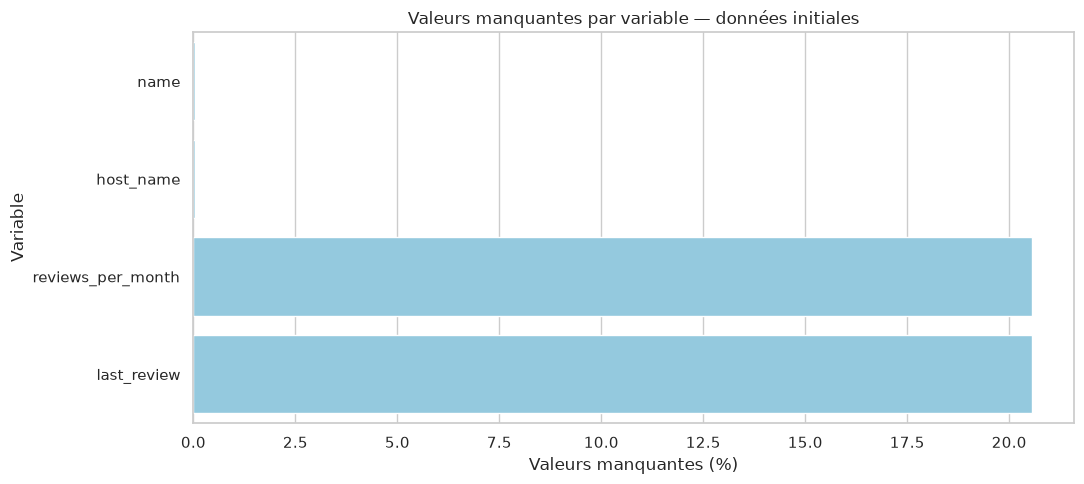

In [7]:
# Pour chaque variable, on calcule le nombre de cases vides et leur proportion.
# mean() appliqué à un masque booléen donne la proportion de valeurs manquantes.
missing_initial = pd.DataFrame({
    "Valeurs manquantes": df_raw.isna().sum(),
    "Pourcentage (%)": (df_raw.isna().mean() * 100).round(2)
}).sort_values("Valeurs manquantes", ascending=False)

display(missing_initial)

# On ne dessine que les variables qui possèdent au moins une valeur manquante.
missing_plot = missing_initial[missing_initial["Valeurs manquantes"] > 0].sort_values("Pourcentage (%)")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(
    data=missing_plot.reset_index(),
    x="Pourcentage (%)", y="index", color="skyblue", ax=ax
)
ax.set_title("Valeurs manquantes par variable — données initiales")
ax.set_xlabel("Valeurs manquantes (%)")
ax.set_ylabel("Variable")
plt.tight_layout()  # Réorganise les marges pour éviter que les étiquettes soient coupées.
plt.show()

### Interprétation du tableau et du graphique des valeurs manquantes

Les absences sont très concentrées dans deux variables liées aux avis : `last_review` et `reviews_per_month` comptent chacune **10 052 valeurs manquantes, soit 20,56 % des annonces**. Les champs `host_name` et `name` ne comportent respectivement que **21 (0,04 %)** et **16 (0,03 %)** valeurs manquantes. Les autres colonnes ne présentent pas de valeur manquante dans le diagnostic initial.

Le graphique confirme visuellement cette concentration : les deux variables relatives aux avis dominent nettement, tandis que les absences des noms sont marginales. Il ne faut cependant pas remplacer automatiquement les 10 052 absences par zéro. Une annonce qui n'a reçu aucun avis peut légitimement ne pas avoir de date de dernier avis ni de moyenne mensuelle. Le contexte métier sera vérifié avant de décider du traitement.

### 5.3 Doublons et premiers contrôles de cohérence

Nous distinguons deux cas :

- les doublons de lignes entièrement identiques, où toutes les colonnes sont répétées ;
- les annonces qui partagent le même identifiant `id`, mais dont certaines informations peuvent différer.

`id` doit normalement identifier une annonce de manière unique. Nous regardons aussi les modalités de quelques variables catégorielles pour détecter d'éventuels espaces ou libellés inattendus.

In [8]:
# duplicated() sans subset recherche les lignes dont toutes les colonnes sont identiques.
print("Lignes entièrement dupliquées :", int(df_raw.duplicated().sum()))

# Un identifiant d'annonce doit normalement être unique.
# keep=False marque toutes les lignes appartenant à un groupe d'identifiants répétés.
if "id" in df_raw.columns:
    print(
        "Lignes appartenant à un groupe d'ID dupliqués :",
        int(df_raw["id"].duplicated(keep=False).sum())
    )
    print(
        "Nombre d'ID dupliqués (hors première occurrence) :",
        int(df_raw["id"].duplicated().sum())
    )

# Afficher les modalités des variables catégorielles afin de repérer les valeurs inattendues.
for col in ["neighbourhood_group", "room_type"]:
    print(f"\nRépartition initiale de {col} :")
    display(df_raw[col].value_counts(dropna=False).to_frame("Effectif"))

Lignes entièrement dupliquées : 0
Lignes appartenant à un groupe d'ID dupliqués : 0
Nombre d'ID dupliqués (hors première occurrence) : 0

Répartition initiale de neighbourhood_group :


,Effectif
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373



Répartition initiale de room_type :


,Effectif
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


### Interprétation des doublons et des catégories

Le diagnostic ne détecte **aucune ligne entièrement dupliquée** et **aucun identifiant d'annonce répété**. Il n'y a donc pas de doublon à retirer sur ces deux critères dans le fichier initial.

La répartition initiale confirme que Manhattan (**21 661 annonces**) et Brooklyn (**20 104**) concentrent la majorité de l'offre. Queens compte **5 666 annonces**, contre **1 091 dans le Bronx** et **373 à Staten Island**. Pour les types de logements, les logements entiers sont les plus nombreux (**25 409**), suivis des chambres privées (**22 326**) et des chambres partagées (**1 160**). Ces premiers effectifs donnent déjà une indication de la structure de l'offre, qui sera recalculée après nettoyage.

### 5.4 Repérage des valeurs aberrantes et des incohérences métier

Nous examinons plusieurs familles de valeurs :

- les prix nuls ou négatifs, qui ne correspondent pas à un tarif de nuitée exploitable ;
- les séjours minimums nuls/négatifs ou très élevés ;
- les disponibilités hors de l'intervalle de 0 à 365 jours ;
- les coordonnées géographiques impossibles ;
- les incohérences entre le nombre d'avis et les champs décrivant les avis.

La règle de l'écart interquartile (IQR) sert à **signaler** des valeurs extrêmes. Une valeur située au-delà des bornes n'est pas forcément une erreur : un logement très cher ou une durée minimale longue peut réellement exister. La décision de correction doit donc tenir compte du sens métier.

In [9]:
# -----------------------------------------------------------------------------
# Fonctions réutilisables pour diagnostiquer la qualité des données
# -----------------------------------------------------------------------------

def serie_numerique(data: pd.DataFrame, colonne: str) -> pd.Series:
    """Retourne une colonne convertie temporairement en numérique.

    errors="coerce" transforme les valeurs impossibles à convertir en NaN.
    La fonction ne modifie pas le DataFrame d'origine.
    """
    if colonne not in data.columns:
        return pd.Series(dtype="float64")
    return pd.to_numeric(data[colonne], errors="coerce")


def bornes_iqr(serie: pd.Series) -> tuple[float, float]:
    """Calcule les bornes inférieure et supérieure de la règle IQR.

    IQR = Q3 - Q1. Une valeur située en dehors de [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]
    est signalée comme atypique. Ce signalement ne prouve pas qu'elle est fausse.
    """
    serie = pd.to_numeric(serie, errors="coerce").dropna()
    if serie.empty:
        return (np.nan, np.nan)

    # Q1 est le 25e percentile et Q3 le 75e percentile.
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr))


def compter_outliers_iqr(serie: pd.Series) -> int:
    """Compte le nombre de valeurs situées hors des bornes IQR."""
    serie = pd.to_numeric(serie, errors="coerce")
    bas, haut = bornes_iqr(serie)
    if pd.isna(bas) or pd.isna(haut):
        return 0
    return int(((serie < bas) | (serie > haut)).sum())


def instantane_qualite(data: pd.DataFrame) -> dict:
    """Calcule un ensemble constant d'indicateurs de qualité.

    La même fonction sera appelée sur le fichier brut puis sur le fichier nettoyé.
    Cela garantit une comparaison avant/après fondée sur les mêmes règles.
    """
    # Conversion temporaire des variables numériques utiles au diagnostic.
    prix = serie_numerique(data, "price")
    nuits = serie_numerique(data, "minimum_nights")
    avis = serie_numerique(data, "number_of_reviews")
    disponibilite = serie_numerique(data, "availability_365")
    latitude = serie_numerique(data, "latitude")
    longitude = serie_numerique(data, "longitude")
    avis_mois = serie_numerique(data, "reviews_per_month")

    # Les dates non vides qui ne peuvent pas être converties sont comptées comme illisibles.
    if "last_review" in data.columns:
        dates = pd.to_datetime(data["last_review"], errors="coerce")
        dates_invalides = int((data["last_review"].notna() & dates.isna()).sum())
    else:
        dates = pd.Series(pd.NaT, index=data.index)
        dates_invalides = 0

    # Distinguer les annonces qui n'ont aucun avis de celles qui ont des avis mais
    # pour lesquelles une information relative aux avis n'est pas renseignée.
    positif_avis = avis > 0
    zero_avis = avis == 0
    date_absente_avec_avis = int((positif_avis & dates.isna()).sum())
    taux_absent_avec_avis = int((positif_avis & avis_mois.isna()).sum())
    champs_avis_absents_sans_avis = int((zero_avis & dates.isna() & avis_mois.isna()).sum())

    # Contrôles sur l'identifiant : présence et unicité.
    if "id" in data.columns:
        id_duplicated_rows = int(data["id"].duplicated(keep=False).sum())
        missing_ids = int(data["id"].isna().sum())
    else:
        id_duplicated_rows, missing_ids = 0, 0

    # Les bornes ci-dessous sont les bornes mathématiques mondiales, pas les limites de NYC.
    coord_invalides = (
        (latitude < -90) | (latitude > 90) |
        (longitude < -180) | (longitude > 180)
    ).fillna(False)

    # Le dictionnaire rassemble tous les indicateurs dans un format facile à comparer.
    return {
        "Lignes": int(data.shape[0]),
        "Colonnes": int(data.shape[1]),
        "Cellules manquantes (total)": int(data.isna().sum().sum()),
        "Lignes entièrement dupliquées": int(data.duplicated().sum()),
        "Lignes avec ID dupliqué": id_duplicated_rows,
        "Identifiants d'annonce manquants": missing_ids,
        "Prix manquants": int(prix.isna().sum()),
        "Prix nuls ou négatifs": int((prix <= 0).sum()),
        "Outliers de prix (règle IQR)": compter_outliers_iqr(prix[prix > 0]),
        "Nuits minimum manquantes": int(nuits.isna().sum()),
        "Nuits minimum <= 0": int((nuits <= 0).sum()),
        "Nuits minimum > 365": int((nuits > 365).sum()),
        "Outliers de nuits minimum (règle IQR)": compter_outliers_iqr(nuits[nuits > 0]),
        "Disponibilité hors [0, 365]": int(((disponibilite < 0) | (disponibilite > 365)).sum()),
        "Coordonnées hors bornes terrestres": int(coord_invalides.sum()),
        "Dates de dernier avis illisibles": dates_invalides,
        "Nom d'annonce manquant": int(data["name"].isna().sum()) if "name" in data else 0,
        "Nom d'hôte manquant": int(data["host_name"].isna().sum()) if "host_name" in data else 0,
        "Date d'avis manquante malgré au moins un avis": date_absente_avec_avis,
        "Moyenne d'avis mensuels manquante malgré au moins un avis": taux_absent_avec_avis,
        "Date et moyenne d'avis absentes sans aucun avis": champs_avis_absents_sans_avis,
    }

# Calculer le diagnostic initial avant toute correction.
snapshot_initial = instantane_qualite(df_raw)
display(pd.Series(snapshot_initial, name="Valeur initiale").to_frame())

# Afficher les bornes IQR des prix et des séjours minimums.
# Pour l'interprétation, on calcule ces bornes sur les valeurs positives seulement.
for col in ["price", "minimum_nights"]:
    s = serie_numerique(df_raw, col)
    low, high = bornes_iqr(s[s > 0])
    print(f"{col} — bornes IQR calculées sur les valeurs positives : [{low:.2f}, {high:.2f}]")

,Valeur initiale
Lignes,48895
Colonnes,16
Cellules manquantes (total),20141
Lignes entièrement dupliquées,0
Lignes avec ID dupliqué,0
Identifiants d'annonce manquants,0
Prix manquants,0
Prix nuls ou négatifs,11
Outliers de prix (règle IQR),2972
Nuits minimum manquantes,0


price — bornes IQR calculées sur les valeurs positives : [-90.00, 334.00]
minimum_nights — bornes IQR calculées sur les valeurs positives : [-5.00, 11.00]


### Interprétation du diagnostic initial de qualité

Le diagnostic relève **11 prix nuls ou négatifs**. Ils ne représentent pas un tarif de nuitée exploitable et seront donc écartés du fichier utilisé pour les comparaisons de prix et la régression. En revanche, il signale **2 972 prix atypiques selon la règle IQR** et **6 607 durées minimales atypiques**. Les bornes supérieures calculées sur les valeurs positives sont de **334 USD pour le prix** et de **11 nuits pour le séjour minimum**.

Ces nombres ne signifient pas que toutes ces annonces sont erronées. La règle IQR identifie des valeurs éloignées du centre de la distribution ; elle ne prouve pas une erreur de saisie. Le fichier contient aussi **14 annonces exigeant plus de 365 nuits minimum**, ce qui est inhabituel pour une location de courte durée et mérite d'être signalé. En revanche, aucune disponibilité hors de `[0, 365]`, aucune coordonnée hors bornes géographiques mondiales et aucune date de dernier avis illisible ne sont détectées.

Enfin, les **10 052 absences simultanées** de `last_review` et `reviews_per_month` correspondent à des annonces sans avis : il s'agit d'une absence potentiellement structurelle, et non nécessairement d'un défaut à corriger.

### 5.5 Première exploration graphique des prix

Les prix sont généralement très asymétriques : quelques annonces très chères peuvent comprimer la majorité des observations sur un graphique. Nous affichons donc aussi un histogramme en échelle logarithmique et un boxplot dont l'axe est limité au 99e percentile. Cette limite est uniquement visuelle ; aucune ligne n'est supprimée à ce stade.

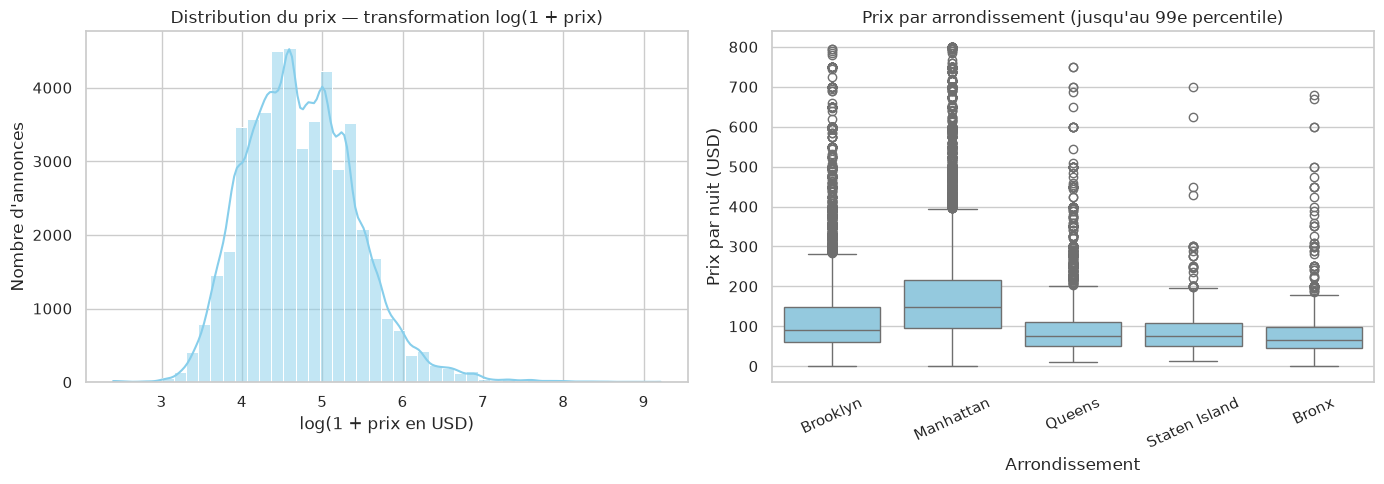

In [10]:
# On crée une copie temporaire pour la visualisation ; df_raw reste inchangé.
eda_initial = df_raw.copy()

# Conversion à la volée pour garantir que les colonnes se comportent comme des nombres.
eda_initial["price"] = pd.to_numeric(eda_initial["price"], errors="coerce")
eda_initial["minimum_nights"] = pd.to_numeric(eda_initial["minimum_nights"], errors="coerce")

# On ignore les prix nuls ou négatifs pour l'histogramme logarithmique.
prix_positifs = eda_initial.loc[eda_initial["price"] > 0, "price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Le logarithme réduit l'effet des prix très élevés et rend visible la distribution centrale.
sns.histplot(np.log1p(prix_positifs), bins=45, kde=True, color="skyblue", ax=axes[0])
axes[0].set_title("Distribution du prix — transformation log(1 + prix)")
axes[0].set_xlabel("log(1 + prix en USD)")
axes[0].set_ylabel("Nombre d'annonces")

# Le boxplot compare les arrondissements en limitant uniquement l'affichage au 99e percentile.
# Les annonces plus chères ne sont pas supprimées du DataFrame.
if "neighbourhood_group" in eda_initial.columns:
    seuil_99 = prix_positifs.quantile(0.99) if not prix_positifs.empty else 0
    sns.boxplot(
        data=eda_initial[eda_initial["price"].between(0, seuil_99)],
        x="neighbourhood_group", y="price", color="skyblue", ax=axes[1]
    )
    axes[1].set_title("Prix par arrondissement (jusqu'au 99e percentile)")
    axes[1].set_xlabel("Arrondissement")
    axes[1].set_ylabel("Prix par nuit (USD)")
    axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### Interprétation des graphiques initiaux des prix

L'histogramme transformé par `log(1 + prix)` permet de mieux voir la concentration des annonces dans les tarifs courants, malgré la présence de quelques montants très élevés. Le boxplot par arrondissement est limité au **99e percentile**, qui vaut ici **799 USD** : cette limite sert uniquement à rendre la figure lisible ; les annonces plus chères restent dans le jeu de données.

Cette visualisation confirme l'asymétrie déjà observée dans les statistiques : la majorité des tarifs se situe très en dessous des annonces les plus chères. C'est pourquoi la médiane sera privilégiée pour décrire le prix typique, et pourquoi les valeurs extrêmes seront conservées lorsqu'elles ne sont pas manifestement impossibles.

## 6. Stratégie de nettoyage et justification des choix

Le nettoyage doit améliorer la fiabilité du fichier sans effacer inutilement des informations. Le tableau ci-dessous présente les décisions prises et leur justification métier.

| Problème | Décision retenue | Justification métier |
|---|---|---|
| Espaces superflus / chaînes vides | Retirer les espaces de début et de fin ; convertir les chaînes vides en valeurs manquantes | Éviter des modalités artificiellement différentes et mieux mesurer les absences. |
| Doublons exacts | Supprimer les lignes entièrement identiques | Elles répètent exactement la même observation. |
| Identifiants `id` dupliqués | Conserver la première occurrence et signaler le nombre de lignes écartées | Une annonce doit être représentée une seule fois. La première occurrence est conservée de façon déterministe. |
| `id` manquant | Écarter la ligne | Sans identifiant d'annonce, l'unicité de l'enregistrement ne peut pas être garantie. |
| Prix nul, négatif ou manquant | Écarter la ligne du fichier destiné à l'analyse des prix | Un prix strictement positif est nécessaire pour comparer les tarifs par nuitée. Le nombre de lignes perdues sera mesuré. |
| `name` ou `host_name` manquant | Remplacer par un libellé explicite | Conserver l'annonce sans inventer un nom réel ; le placeholder indique clairement l'absence d'information. |
| `last_review` | Convertir en date ; les dates illisibles deviennent `NaT` | Permettre les analyses temporelles sans inventer une date. |
| Champs d'avis absents pour zéro avis | Conserver les valeurs manquantes | Il s'agit d'une absence structurelle, pas nécessairement d'une erreur. |
| Valeurs négatives dans les compteurs / disponibilités hors plage | Convertir en valeur manquante | Un compte ne peut pas être négatif et une disponibilité annuelle doit être comprise entre 0 et 365 jours. La ligne reste utile pour les autres variables. |
| Coordonnées hors bornes géographiques mondiales | Remplacer les coordonnées invalides par des valeurs manquantes | Une coordonnée impossible ne doit pas être utilisée sur une carte ; l'annonce peut rester utile pour les prix. |
| Prix élevés et séjours minimums extrêmes | Conserver et signaler | Une annonce chère ou un séjour long peut être réel. L'IQR est un outil de détection, pas une preuve d'erreur. |

Les corrections sont consignées dans un journal. Les suppressions seront quantifiées pour mesurer la perte de données.

In [11]:
# On repart d'une copie intacte des données originales : le DataFrame df_raw ne sera jamais modifié.
df_clean = df_raw.copy(deep=True)

# Le journal enregistrera chaque famille de corrections, son volume et sa justification.
journal = []


def enregistrer_action(probleme: str, action: str, nombre: int, justification: str) -> None:
    """Ajoute une correction au journal de nettoyage pour garder une trace des choix."""
    journal.append({
        "Problème": probleme,
        "Action réalisée": action,
        "Nombre de valeurs/lignes concernées": int(nombre),
        "Justification": justification,
    })

# -----------------------------------------------------------------------------
# 1) Harmonisation des colonnes textuelles
# -----------------------------------------------------------------------------
# strip() retire les espaces inutiles au début et à la fin des textes.
# Une chaîne vide est ensuite remplacée par une vraie valeur manquante (NA).
colonnes_texte = df_clean.select_dtypes(include=["object", "string"]).columns.tolist()
chaines_vides = 0
for col in colonnes_texte:
    texte = df_clean[col].astype("string").str.strip()
    chaines_vides += int((texte == "").sum())
    df_clean[col] = texte.replace("", pd.NA)

enregistrer_action(
    "Espaces superflus et chaînes vides",
    "Suppression des espaces externes et conversion des chaînes vides en NA",
    chaines_vides,
    "Éviter les fausses modalités et rendre les absences détectables."
)

# -----------------------------------------------------------------------------
# 2) Conversion explicite des colonnes numériques
# -----------------------------------------------------------------------------
# to_numeric() convertit les valeurs en nombres. Une valeur illisible devient NA
# grâce à errors='coerce', ce qui évite de bloquer le nettoyage.
colonnes_numeriques = [
    "id", "host_id", "latitude", "longitude", "price", "minimum_nights",
    "number_of_reviews", "reviews_per_month", "calculated_host_listings_count",
    "availability_365"
]
conversions_invalides = 0
for col in colonnes_numeriques:
    avant_non_manquant = df_clean[col].notna()
    converti = pd.to_numeric(df_clean[col], errors="coerce")
    conversions_invalides += int((avant_non_manquant & converti.isna()).sum())
    df_clean[col] = converti

enregistrer_action(
    "Colonnes numériques stockées sous un type non numérique ou contenant des valeurs illisibles",
    "Conversion avec pandas.to_numeric(errors='coerce')",
    conversions_invalides,
    "Garantir des calculs statistiques cohérents ; les valeurs non interprétables deviennent manquantes."
)

# Ces variables représentent des nombres entiers : identifiants, comptes, nuits et jours.
# Le type pandas Int64 (I majuscule) accepte à la fois des entiers et des valeurs manquantes.
colonnes_entieres = [
    "id", "host_id", "minimum_nights", "number_of_reviews",
    "calculated_host_listings_count", "availability_365"
]
valeurs_non_entieres = 0
for col in colonnes_entieres:
    # Une partie décimale dans un compte entier est considérée comme non exploitable.
    non_entier = df_clean[col].notna() & (df_clean[col] % 1 != 0)
    valeurs_non_entieres += int(non_entier.sum())
    df_clean.loc[non_entier, col] = np.nan
    df_clean[col] = df_clean[col].astype("Int64")

enregistrer_action(
    "Valeurs décimales dans les variables qui doivent être des nombres entiers",
    "Conversion de ces valeurs en NA puis typage entier nullable",
    valeurs_non_entieres,
    "Un identifiant, un nombre d'avis, un nombre de nuits ou de jours doit être entier."
)

# Les coordonnées, prix et moyennes mensuelles peuvent contenir des décimales.
for col in ["latitude", "longitude", "price", "reviews_per_month"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce").astype("Float64")

# -----------------------------------------------------------------------------
# 3) Conversion de la date du dernier avis
# -----------------------------------------------------------------------------
# to_datetime() transforme les textes reconnus en dates. Une date illisible devient NaT.
dates_initialement_renseignees = df_clean["last_review"].notna()
dates_converties = pd.to_datetime(df_clean["last_review"], errors="coerce")
dates_illisibles = int((dates_initialement_renseignees & dates_converties.isna()).sum())
df_clean["last_review"] = dates_converties

enregistrer_action(
    "Date du dernier avis",
    "Conversion en datetime ; dates illisibles converties en NaT",
    dates_illisibles,
    "Permettre les traitements temporels sans fabriquer de dates."
)

# -----------------------------------------------------------------------------
# 4) Suppression des doublons exacts
# -----------------------------------------------------------------------------
# Une ligne entièrement identique à une autre n'apporte pas d'information supplémentaire.
n_avant = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first")
n_supprimees = n_avant - len(df_clean)

enregistrer_action(
    "Doublons exacts",
    "Suppression des lignes entièrement identiques",
    n_supprimees,
    "Une copie exacte n'apporte aucune information supplémentaire."
)

# -----------------------------------------------------------------------------
# 5) Vérification de l'identifiant d'annonce
# -----------------------------------------------------------------------------
# Sans id, nous ne pouvons pas garantir le suivi et l'unicité d'une annonce.
n_avant = len(df_clean)
df_clean = df_clean[df_clean["id"].notna()].copy()
n_id_absent = n_avant - len(df_clean)

enregistrer_action(
    "Identifiant d'annonce manquant",
    "Suppression des lignes sans id",
    n_id_absent,
    "L'unicité et le suivi de l'annonce ne peuvent pas être garantis sans identifiant."
)

# Une annonce ne doit apparaître qu'une fois. Nous conservons la première occurrence de chaque id.
n_avant = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["id"], keep="first").copy()
n_id_duplique = n_avant - len(df_clean)

enregistrer_action(
    "Identifiants d'annonce dupliqués",
    "Conservation de la première ligne pour chaque id",
    n_id_duplique,
    "Une annonce ne doit apparaître qu'une seule fois dans le fichier final."
)

# -----------------------------------------------------------------------------
# 6) Contrôle du prix, variable centrale de l'analyse et de la régression
# -----------------------------------------------------------------------------
# Les prix manquants, nuls ou négatifs ne peuvent pas servir de tarifs de nuitée.
n_avant = len(df_clean)
masque_prix_valide = df_clean["price"].notna() & (df_clean["price"] > 0)
df_clean = df_clean.loc[masque_prix_valide].copy()
n_prix_ecartes = n_avant - len(df_clean)

enregistrer_action(
    "Prix nul, négatif ou manquant",
    "Exclusion des annonces dont le prix n'est pas strictement positif",
    n_prix_ecartes,
    "Un tarif nul/négatif ou absent ne permet pas l'analyse fiable du prix d'une nuit. Les pertes sont mesurées."
)

# -----------------------------------------------------------------------------
# 7) Valeurs impossibles : invalider la variable plutôt que supprimer toute l'annonce
# -----------------------------------------------------------------------------
# Exemples : un compteur ne peut pas être négatif et la disponibilité annuelle
# doit être comprise entre 0 et 365 jours. On remplace uniquement la cellule fautive par NA.
regles_na = {
    "minimum_nights": df_clean["minimum_nights"] <= 0,
    "number_of_reviews": df_clean["number_of_reviews"] < 0,
    "reviews_per_month": df_clean["reviews_per_month"] < 0,
    "calculated_host_listings_count": df_clean["calculated_host_listings_count"] <= 0,
    "availability_365": (df_clean["availability_365"] < 0) | (df_clean["availability_365"] > 365),
}
for col, masque in regles_na.items():
    # fillna(False) évite de traiter une valeur déjà manquante comme une anomalie.
    nombre = int(masque.fillna(False).sum())
    df_clean.loc[masque.fillna(False), col] = pd.NA
    enregistrer_action(
        f"Valeurs hors domaine dans {col}",
        "Remplacement des valeurs invalides par NA, sans supprimer toute l'annonce",
        nombre,
        "La valeur de cette variable n'est pas exploitable, mais les autres informations de l'annonce peuvent rester utiles."
    )

# Les bornes mondiales sont -90 à 90 pour la latitude et -180 à 180 pour la longitude.
# Une coordonnée invalide est remplacée par NA afin de conserver le reste de l'annonce.
coord_invalides_lat = ((df_clean["latitude"] < -90) | (df_clean["latitude"] > 90)).fillna(False)
coord_invalides_lon = ((df_clean["longitude"] < -180) | (df_clean["longitude"] > 180)).fillna(False)
n_coord_invalides = int((coord_invalides_lat | coord_invalides_lon).sum())
df_clean.loc[coord_invalides_lat, "latitude"] = pd.NA
df_clean.loc[coord_invalides_lon, "longitude"] = pd.NA

enregistrer_action(
    "Coordonnées géographiques hors bornes mondiales",
    "Remplacement des coordonnées impossibles par NA",
    n_coord_invalides,
    "Éviter de placer des points impossibles sur une carte sans perdre les autres champs de l'annonce."
)

# -----------------------------------------------------------------------------
# 8) Traitement des champs textuels importants
# -----------------------------------------------------------------------------
# Nous conservons les annonces dont certaines informations descriptives manquent.
# Le placeholder rend l'absence visible ; il ne prétend pas donner le vrai nom.
for col, placeholder, libelle in [
    ("name", "Annonce sans nom renseigné", "Titre d'annonce manquant"),
    ("host_name", "Hôte non renseigné", "Nom d'hôte manquant"),
    ("neighbourhood_group", "Arrondissement non renseigné", "Arrondissement manquant"),
    ("neighbourhood", "Quartier non renseigné", "Quartier manquant"),
    ("room_type", "Type de logement non renseigné", "Type de logement manquant"),
]:
    nombre = int(df_clean[col].isna().sum())
    df_clean[col] = df_clean[col].fillna(placeholder)
    enregistrer_action(
        libelle,
        f"Remplacement par le libellé '{placeholder}'",
        nombre,
        "Conserver la ligne tout en indiquant explicitement que l'information n'est pas renseignée."
    )

# On remet les colonnes dans l'ordre initial pour faciliter la comparaison et l'export.
df_clean = df_clean[colonnes_attendues].reset_index(drop=True)

print("Nettoyage terminé.")
print("Lignes avant :", len(df_raw))
print("Lignes après :", len(df_clean))
print("Lignes retirées :", len(df_raw) - len(df_clean))

# Le journal des actions permet de justifier chaque décision pendant la restitution.
display(pd.DataFrame(journal))

Nettoyage terminé.
Lignes avant : 48895
Lignes après : 48884
Lignes retirées : 11


,Problème,Action réalisée,Nombre de valeurs/lignes concernées,Justification
0,Espaces superflus et chaînes vides,Suppression des espaces externes et conversion...,0,Éviter les fausses modalités et rendre les abs...
1,Colonnes numériques stockées sous un type non ...,Conversion avec pandas.to_numeric(errors='coer...,0,Garantir des calculs statistiques cohérents ; ...
2,Valeurs décimales dans les variables qui doive...,Conversion de ces valeurs en NA puis typage en...,0,"Un identifiant, un nombre d'avis, un nombre de..."
3,Date du dernier avis,Conversion en datetime ; dates illisibles conv...,0,Permettre les traitements temporels sans fabri...
4,Doublons exacts,Suppression des lignes entièrement identiques,0,Une copie exacte n'apporte aucune information ...
5,Identifiant d'annonce manquant,Suppression des lignes sans id,0,L'unicité et le suivi de l'annonce ne peuvent ...
6,Identifiants d'annonce dupliqués,Conservation de la première ligne pour chaque id,0,Une annonce ne doit apparaître qu'une seule fo...
7,"Prix nul, négatif ou manquant",Exclusion des annonces dont le prix n'est pas ...,11,Un tarif nul/négatif ou absent ne permet pas l...
8,Valeurs hors domaine dans minimum_nights,"Remplacement des valeurs invalides par NA, san...",0,La valeur de cette variable n'est pas exploita...
9,Valeurs hors domaine dans number_of_reviews,"Remplacement des valeurs invalides par NA, san...",0,La valeur de cette variable n'est pas exploita...


### Interprétation du journal complet de nettoyage

Le journal montre que plusieurs opérations ont été appliquées sans entraîner de suppression de lignes : harmonisation des textes, conversion des types numériques et de la date, contrôle des compteurs et vérification des coordonnées. Les **16 titres d'annonce manquants** et les **21 noms d'hôtes manquants** ont été remplacés par des libellés explicites. Cela conserve les annonces sans inventer de noms réels.

La seule opération qui retire effectivement des annonces est le contrôle du prix : **11 lignes** sont exclues parce que leur prix est nul ou négatif. Aucune ligne n'est supprimée pour doublon, identifiant absent ou doublon d'identifiant, car le diagnostic initial n'en avait détecté aucun. Les valeurs de prix élevées et les durées minimales atypiques ne sont pas supprimées automatiquement.

## 7. Journal des corrections et quantification des pertes

Le nettoyage produit un journal qui indique, pour chaque problème, l'action effectuée, le nombre de valeurs ou de lignes concernées et la justification.

Cette traçabilité est importante : elle permet d'expliquer les choix au lieu de simplement présenter un CSV qui semble propre. La cellule suivante présente notamment les opérations qui ont supprimé des lignes entières.

In [12]:
# Convertir le journal en DataFrame pour sélectionner facilement les actions qui ont retiré des lignes.
journal_df = pd.DataFrame(journal)

print("Bilan des suppressions de lignes :")

# On repère les actions dont le nom indique une suppression, une exclusion ou une déduplication.
# Les autres opérations remplacent une valeur dans une cellule sans retirer toute l'annonce.
masque_suppressions = journal_df["Action réalisée"].str.contains(
    "Suppression|Exclusion|Conservation de la première",
    case=False,
    regex=True
)
display(journal_df.loc[
    masque_suppressions,
    ["Problème", "Action réalisée", "Nombre de valeurs/lignes concernées", "Justification"]
])

# Calculer la proportion de lignes conservées et retirées par rapport au fichier initial.
print("\nPart des lignes conservées : {:.2f}%".format(100 * len(df_clean) / len(df_raw)))
print("Part des lignes retirées : {:.2f}%".format(100 * (len(df_raw) - len(df_clean)) / len(df_raw)))

Bilan des suppressions de lignes :


,Problème,Action réalisée,Nombre de valeurs/lignes concernées,Justification
0,Espaces superflus et chaînes vides,Suppression des espaces externes et conversion...,0,Éviter les fausses modalités et rendre les abs...
4,Doublons exacts,Suppression des lignes entièrement identiques,0,Une copie exacte n'apporte aucune information ...
5,Identifiant d'annonce manquant,Suppression des lignes sans id,0,L'unicité et le suivi de l'annonce ne peuvent ...
6,Identifiants d'annonce dupliqués,Conservation de la première ligne pour chaque id,0,Une annonce ne doit apparaître qu'une seule fo...
7,"Prix nul, négatif ou manquant",Exclusion des annonces dont le prix n'est pas ...,11,Un tarif nul/négatif ou absent ne permet pas l...



Part des lignes conservées : 99.98%
Part des lignes retirées : 0.02%


### Interprétation du bilan des suppressions

Le tableau confirme que **11 annonces seulement** sont retirées, toutes à cause d'un prix nul ou négatif. Le nombre de lignes passe donc de **48 895 à 48 884**. La part conservée est de **99,98 %**, contre **0,02 %** retirée.

Ce taux de conservation élevé montre que le nettoyage a été ciblé : nous avons écarté uniquement les annonces qui ne permettaient pas d'analyser un tarif positif, tout en conservant les observations atypiques qui peuvent correspondre à de véritables situations de marché. Les autres corrections portent sur des cellules ou des formats, pas sur la suppression d'annonces.

## 8. État des lieux final — après nettoyage

Nous recalculons les indicateurs de la section 5 avec la même fonction. La comparaison « avant / après » permet de montrer l'effet réel des corrections.

Un fichier nettoyé n'a pas nécessairement zéro valeur manquante. Certaines absences sont cohérentes avec le fonctionnement des annonces, notamment les informations d'avis pour une annonce qui n'a reçu aucun avis.

In [13]:
# On recalcule exactement les mêmes indicateurs que dans l'état des lieux initial.
snapshot_final = instantane_qualite(df_clean)

# Les deux séries sont alignées par nom d'indicateur dans un même tableau.
comparaison = pd.DataFrame({
    "Avant nettoyage": pd.Series(snapshot_initial),
    "Après nettoyage": pd.Series(snapshot_final),
})

# La différence montre l'évolution de chaque indicateur.
# Pour les anomalies, une diminution est généralement souhaitable ; pour les lignes,
# le résultat doit être interprété en tenant compte des annonces retirées.
comparaison["Évolution (après - avant)"] = comparaison["Après nettoyage"] - comparaison["Avant nettoyage"]
display(comparaison)

# Les valeurs manquantes restantes sont affichées variable par variable.
# Elles ne sont pas nécessairement toutes des erreurs : certaines sont structurelles.
print("\nValeurs manquantes restantes par variable :")
missing_final = pd.DataFrame({
    "Valeurs manquantes": df_clean.isna().sum(),
    "Pourcentage (%)": (df_clean.isna().mean() * 100).round(2)
}).sort_values("Valeurs manquantes", ascending=False)
display(missing_final)

# Vérifier les types finaux après conversion et nettoyage.
print("\nTypes finaux :")
display(df_clean.dtypes.rename("type final").to_frame())

,Avant nettoyage,Après nettoyage,Évolution (après - avant)
Lignes,48895,48884,-11
Colonnes,16,16,0
Cellules manquantes (total),20141,20102,-39
Lignes entièrement dupliquées,0,0,0
Lignes avec ID dupliqué,0,0,0
Identifiants d'annonce manquants,0,0,0
Prix manquants,0,0,0
Prix nuls ou négatifs,11,0,-11
Outliers de prix (règle IQR),2972,2972,0
Nuits minimum manquantes,0,0,0



Valeurs manquantes restantes par variable :


,Valeurs manquantes,Pourcentage (%)
last_review,10051,20.56
reviews_per_month,10051,20.56
id,0,0.00
name,0,0.00
neighbourhood_group,0,0.00
neighbourhood,0,0.00
host_id,0,0.00
host_name,0,0.00
longitude,0,0.00
latitude,0,0.00



Types finaux :


,type final
id,Int64
name,string
host_id,Int64
host_name,string
neighbourhood_group,string
neighbourhood,string
latitude,Float64
longitude,Float64
room_type,string
price,Float64


### Interprétation de la comparaison avant / après nettoyage

La comparaison montre que le nombre de lignes passe de **48 895 à 48 884** et que les **11 prix nuls ou négatifs** disparaissent. Les colonnes `name` et `host_name` ne présentent plus de valeurs manquantes, car les absences ont été remplacées par des libellés explicites.

Le total des cellules manquantes diminue de **20 141 à 20 102** (soit 39 cellules de moins). Cette baisse correspond aux 16 titres et 21 noms d'hôtes renseignés par des libellés, compensés par le retrait de lignes qui comportaient elles-mêmes des informations manquantes dans les champs d'avis. Les valeurs atypiques de prix restent au nombre de **2 972** : c'est volontaire, car elles n'ont pas été jugées automatiquement invalides. Les valeurs atypiques de nuits minimum passent de **6 607 à 6 605**, à la suite du retrait des 11 annonces non tarifables.

Le tableau des types confirme également que les variables ont maintenant des formats adaptés : identifiants et compteurs en entiers nullable, prix et mesures continues en numérique, et `last_review` en date. Le fichier nettoyé est donc plus cohérent, sans être artificiellement vidé de toutes ses absences.

### 8.1 Interprétation des valeurs manquantes restantes

Avant de conclure que le fichier est propre, il faut distinguer :

- **Absence structurelle :** `last_review` et `reviews_per_month` peuvent être manquants lorsque `number_of_reviews == 0`. Cette absence est cohérente avec l'absence d'avis.
- **Information inconnue :** si une annonce a reçu des avis mais que la date ou la moyenne mensuelle manque, le champ reste manquant. Nous ne pouvons pas reconstruire cette information à partir des autres colonnes.
- **Noms remplacés par des placeholders :** les libellés ajoutés indiquent l'absence d'un nom sans inventer une identité.

Il est donc normal que le total des valeurs manquantes ne soit pas nécessairement égal à zéro.

In [14]:
# Nous vérifions le sens des absences dans les variables liées aux avis.
# Une annonce sans avis peut légitimement ne pas avoir de date de dernier avis ni de moyenne mensuelle.
nb_avis = pd.to_numeric(df_clean["number_of_reviews"], errors="coerce")

date_absente_zero_avis = int(((nb_avis == 0) & df_clean["last_review"].isna()).sum())
taux_absent_zero_avis = int(((nb_avis == 0) & df_clean["reviews_per_month"].isna()).sum())

# Si une annonce a déjà des avis, une date ou une moyenne manquante constitue un autre cas.
date_absente_avec_avis = int(((nb_avis > 0) & df_clean["last_review"].isna()).sum())
taux_absent_avec_avis = int(((nb_avis > 0) & df_clean["reviews_per_month"].isna()).sum())

print("Annonces sans avis et sans date de dernier avis :", date_absente_zero_avis)
print("Annonces sans avis et sans moyenne mensuelle :", taux_absent_zero_avis)
print("Annonces avec avis mais date manquante :", date_absente_avec_avis)
print("Annonces avec avis mais moyenne mensuelle manquante :", taux_absent_avec_avis)

Annonces sans avis et sans date de dernier avis : 10051
Annonces sans avis et sans moyenne mensuelle : 10051
Annonces avec avis mais date manquante : 0
Annonces avec avis mais moyenne mensuelle manquante : 0


### Interprétation des valeurs manquantes restantes

Les contrôles confirment que **10 051 annonces** n'ont aucun avis et n'ont donc ni date de dernier avis ni moyenne d'avis mensuels. En revanche, **aucune annonce ayant au moins un avis** ne présente une date ou une moyenne mensuelle manquante.

Cette vérification est essentielle : les 20,56 % de valeurs manquantes encore observées dans les deux colonnes ne traduisent pas ici une information oubliée pour des annonces évaluées. Elles correspondent à des annonces sans avis. Les conserver comme valeurs manquantes préserve donc la distinction entre « aucun avis reçu » et une moyenne d'avis égale à zéro.

## 9. Analyse exploratoire des données (EDA) après nettoyage

L'EDA (*Exploratory Data Analysis*) sert à comprendre les caractéristiques principales des annonces et à faire ressortir des tendances descriptives.

Cette partie répond à la problématique touristique : répartition de l'offre, prix par arrondissement, prix par type d'hébergement, répartition géographique et durée minimale de séjour.

**Attention :** lorsqu'un graphique limite l'axe des prix au 99e percentile ou masque les marqueurs extrêmes d'un boxplot, cette limite sert uniquement à rendre le graphique lisible. Les annonces concernées restent dans `df_clean` et dans le CSV final.

### 9.1 Répartition de l'offre par arrondissement

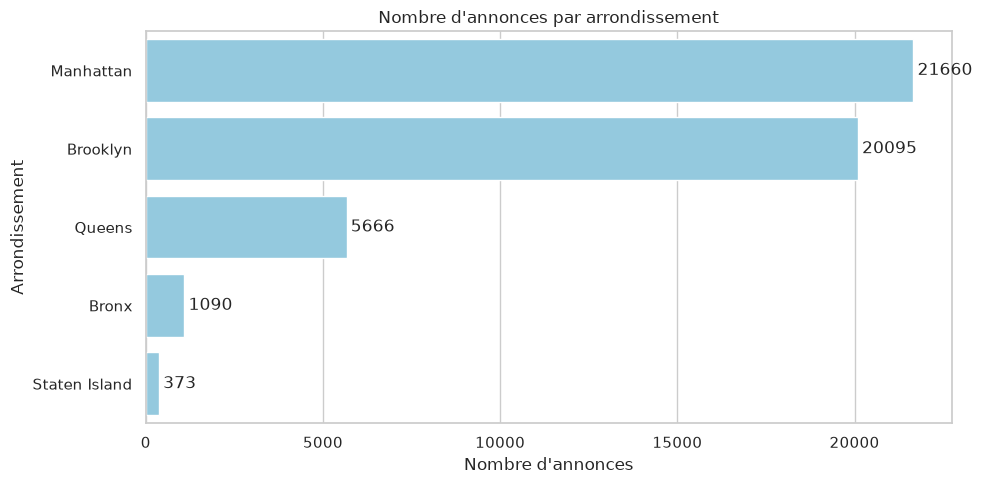

,Nombre d'annonces,Part (%)
Arrondissement,,
Manhattan,21660,44.31
Brooklyn,20095,41.11
Queens,5666,11.59
Bronx,1090,2.23
Staten Island,373,0.76


In [15]:
# On ordonne les arrondissements du plus représenté au moins représenté.
ordre_arrondissements = df_clean["neighbourhood_group"].value_counts().index.tolist()

# countplot compte le nombre d'annonces dans chaque catégorie.
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(
    data=df_clean, y="neighbourhood_group",
    order=ordre_arrondissements, color="skyblue", ax=ax
)
ax.set_title("Nombre d'annonces par arrondissement")
ax.set_xlabel("Nombre d'annonces")
ax.set_ylabel("Arrondissement")

# bar_label écrit les effectifs au bout des barres pour faciliter leur lecture.
for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

# Le tableau donne aussi la part de chaque arrondissement dans l'ensemble des annonces.
repartition_arrondissements = (
    df_clean["neighbourhood_group"].value_counts()
    .rename_axis("Arrondissement").to_frame("Nombre d'annonces")
)
repartition_arrondissements["Part (%)"] = (
    100 * repartition_arrondissements["Nombre d'annonces"] / len(df_clean)
).round(2)
display(repartition_arrondissements)

### Interprétation de la répartition par arrondissement

Manhattan arrive en tête avec **21 660 annonces, soit 44,31 %** de l'offre du fichier nettoyé. Brooklyn suit de près avec **20 095 annonces (41,11 %)**. À eux deux, ces arrondissements regroupent environ **85,42 %** des annonces. Queens représente **11,59 %**, le Bronx **2,23 %** et Staten Island **0,76 %**.

Le graphique et le tableau montrent donc une forte concentration géographique de l'offre dans Manhattan et Brooklyn. Pour l'analyse touristique, cela signifie que les caractéristiques de ces deux arrondissements auront un poids important dans les statistiques globales. Il faudra garder à l'esprit que les résultats moyens de New York sont largement influencés par ces deux zones.

### 9.2 Répartition des types de logements

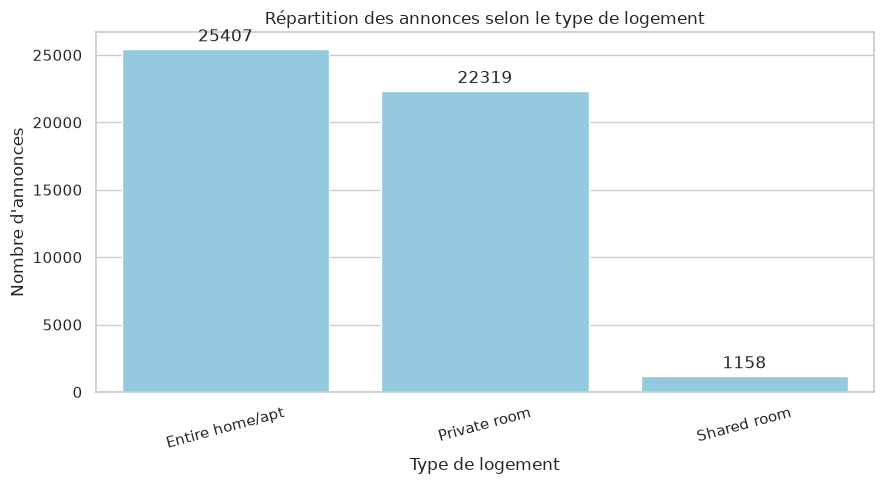

,Part (%)
room_type,
Entire home/apt,51.97
Private room,45.66
Shared room,2.37


In [16]:
# On prépare l'ordre des catégories selon leur fréquence dans le fichier nettoyé.
ordre_types = df_clean["room_type"].value_counts().index.tolist()

# countplot représente le nombre d'annonces pour chaque type de logement.
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=df_clean, x="room_type", order=ordre_types, color="skyblue", ax=ax)
ax.set_title("Répartition des annonces selon le type de logement")
ax.set_xlabel("Type de logement")
ax.set_ylabel("Nombre d'annonces")
ax.tick_params(axis="x", rotation=15)

# Ajouter les effectifs au-dessus des barres pour rendre le graphique plus facile à lire.
for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

# Le pourcentage complète les effectifs et facilite la comparaison entre catégories.
repartition_types = (
    df_clean["room_type"].value_counts(normalize=True)
    .mul(100).round(2).rename("Part (%)").to_frame()
)
display(repartition_types)

### Interprétation de la répartition des types de logements

Les logements entiers (`Entire home/apt`) représentent **51,97 %** des annonces nettoyées, juste devant les chambres privées (`Private room`) à **45,66 %**. Les chambres partagées ne constituent que **2,37 %** de l'offre.

L'offre observée est donc principalement composée de logements entiers et de chambres privées, dont les parts sont relativement proches. Les chambres partagées restent marginales. Cette composition est importante pour comprendre les prix : comparer toutes les annonces sans distinguer le type d'hébergement mélangerait des produits touristiques différents.

### 9.3 Distribution des prix par nuit

Le prix est étudié sur une échelle logarithmique pour mieux visualiser les valeurs les plus fréquentes malgré une distribution potentiellement très asymétrique.

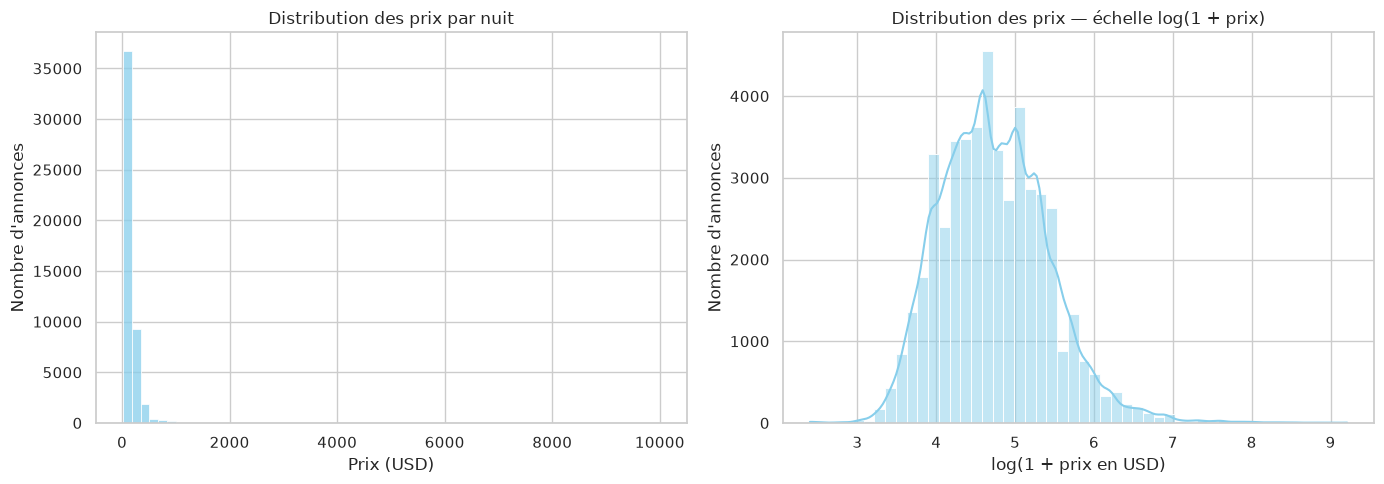

Prix médian : $106.00
Prix moyen : $152.76
Prix minimum : $10.00
Prix maximum : $10,000.00


In [17]:
# La variable price est convertie en float pour les calculs et les graphiques.
prix = df_clean["price"].dropna().astype(float)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Premier graphique : prix en dollars sur l'échelle habituelle.
sns.histplot(prix, bins=60, color="skyblue", ax=axes[0])
axes[0].set_title("Distribution des prix par nuit")
axes[0].set_xlabel("Prix (USD)")
axes[0].set_ylabel("Nombre d'annonces")

# Deuxième graphique : transformation log(1 + prix) pour atténuer visuellement l'asymétrie.
sns.histplot(np.log1p(prix), bins=50, kde=True, color="skyblue", ax=axes[1])
axes[1].set_title("Distribution des prix — échelle log(1 + prix)")
axes[1].set_xlabel("log(1 + prix en USD)")
axes[1].set_ylabel("Nombre d'annonces")

plt.tight_layout()
plt.show()

# La médiane est moins sensible aux prix extrêmes que la moyenne.
print("Prix médian : ${:,.2f}".format(prix.median()))
print("Prix moyen : ${:,.2f}".format(prix.mean()))
print("Prix minimum : ${:,.2f}".format(prix.min()))
print("Prix maximum : ${:,.2f}".format(prix.max()))

### Interprétation de la distribution des prix

Après nettoyage, le prix médian est de **106 USD par nuit**, tandis que le prix moyen atteint **152,76 USD**. Le minimum observé est de **10 USD** et le maximum de **10 000 USD**.

La moyenne nettement supérieure à la médiane confirme une distribution asymétrique vers les prix élevés : un petit nombre d'annonces très chères tire la moyenne vers le haut. La médiane est donc plus représentative du tarif d'une annonce « typique ». Le second histogramme, en échelle `log(1 + prix)`, comprime visuellement les grandes valeurs et permet de mieux examiner la partie centrale de la distribution. Les prix élevés restent toutefois présents dans les données et pourront expliquer une partie des erreurs de prédiction.

### 9.4 Comparaison des prix entre arrondissements

Le boxplot montre la dispersion des prix par arrondissement. L'affichage est limité au 99e percentile pour que la partie centrale soit lisible ; les prix supérieurs ne sont pas supprimés du jeu de données.

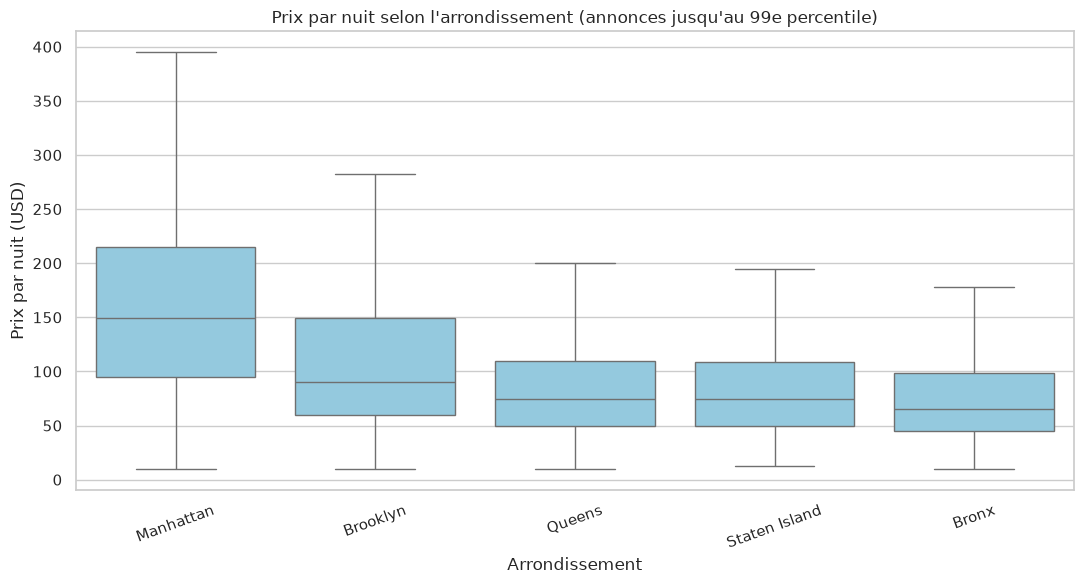

,nombre_annonces,prix_median,prix_moyen
neighbourhood_group,,,
Manhattan,21660,150.0,196.88
Brooklyn,20095,90.0,124.44
Queens,5666,75.0,99.52
Staten Island,373,75.0,114.81
Bronx,1090,65.0,87.58


In [18]:
# Le 99e percentile sert uniquement à limiter l'affichage des prix les plus élevés.
# Les lignes correspondantes restent présentes dans df_clean.
q99_prix = df_clean["price"].quantile(0.99)
df_prix_graph = df_clean[df_clean["price"] <= q99_prix].copy()

# Classer les arrondissements selon leur prix médian, du plus élevé au moins élevé.
ordre_arrondissements = (
    df_clean.groupby("neighbourhood_group")["price"]
    .median().sort_values(ascending=False).index.tolist()
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=df_prix_graph, x="neighbourhood_group", y="price",
    order=ordre_arrondissements, showfliers=False, color="skyblue", ax=ax
)
ax.set_title("Prix par nuit selon l'arrondissement (annonces jusqu'au 99e percentile)")
ax.set_xlabel("Arrondissement")
ax.set_ylabel("Prix par nuit (USD)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Le tableau donne des statistiques de prix et le nombre d'annonces dans chaque arrondissement.
prix_arrondissements = (
    df_clean.groupby("neighbourhood_group")["price"]
    .agg(nombre_annonces="count", prix_median="median", prix_moyen="mean")
    .sort_values("prix_median", ascending=False)
)
display(prix_arrondissements.round(2))

### Interprétation des prix par arrondissement

Manhattan présente le prix médian le plus élevé : **150 USD par nuit**, avec un prix moyen de **196,88 USD**. Brooklyn suit avec une médiane de **90 USD** et une moyenne de **124,44 USD**. Queens et Staten Island ont la même médiane (**75 USD**), mais des moyennes différentes (**99,52 USD** et **114,81 USD**). Le Bronx présente la médiane la plus faible (**65 USD**) et une moyenne de **87,58 USD**.

Le boxplot montre la dispersion des tarifs au sein de chaque arrondissement ; les prix au-dessus du 99e percentile ne sont pas affichés afin de préserver la lisibilité, mais ils restent dans le tableau et dans le fichier nettoyé. Le fait que la moyenne de Staten Island dépasse celle de Queens malgré une médiane identique peut être lié à quelques annonces plus chères. Il faut également rester prudent pour Staten Island, dont l'effectif est beaucoup plus faible (**373 annonces**) que ceux de Manhattan et Brooklyn.

Ces résultats décrivent des différences de prix entre lieux ; ils ne démontrent pas à eux seuls que la localisation est la cause de ces écarts.

### 9.5 Prix selon le type de logement

Cette comparaison permet de voir si les logements entiers, les chambres privées et les chambres partagées présentent des niveaux de prix différents.

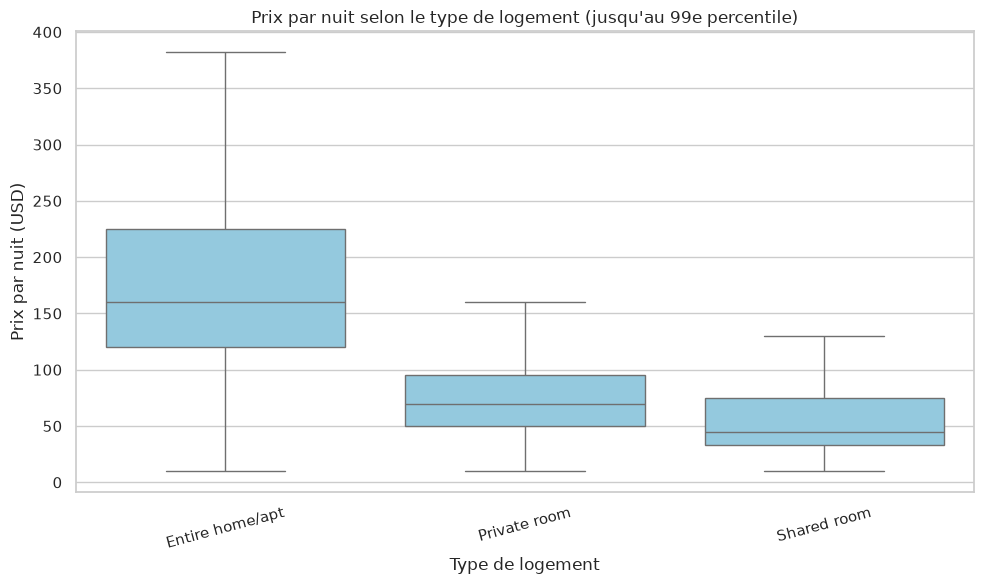

,nombre_annonces,prix_median,prix_moyen
room_type,,,
Entire home/apt,25407,160.0,211.81
Private room,22319,70.0,89.81
Shared room,1158,45.0,70.25


In [19]:
# Déterminer l'ordre des types de logement selon leur prix médian décroissant.
ordre_types_prix = (
    df_clean.groupby("room_type")["price"]
    .median().sort_values(ascending=False).index.tolist()
)

# Le boxplot permet de comparer la médiane, la dispersion et les quartiles des prix.
# Le jeu affiché est limité au 99e percentile pour ne pas écraser les boîtes.
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df_prix_graph, x="room_type", y="price",
    order=ordre_types_prix, showfliers=False, color="skyblue", ax=ax
)
ax.set_title("Prix par nuit selon le type de logement (jusqu'au 99e percentile)")
ax.set_xlabel("Type de logement")
ax.set_ylabel("Prix par nuit (USD)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

# Comparaison chiffrée pour compléter l'interprétation du graphique.
prix_types = (
    df_clean.groupby("room_type")["price"]
    .agg(nombre_annonces="count", prix_median="median", prix_moyen="mean")
    .sort_values("prix_median", ascending=False)
)
display(prix_types.round(2))

### Interprétation des prix selon le type de logement

Les différences sont nettes : un logement entier présente une médiane de **160 USD** et une moyenne de **211,81 USD** par nuit. Pour une chambre privée, la médiane est de **70 USD** et la moyenne de **89,81 USD**. Une chambre partagée affiche la médiane la plus basse (**45 USD**) et une moyenne de **70,25 USD**.

Le graphique confirme que les logements entiers sont généralement plus chers, tandis que les chambres partagées sont les moins chères. Dans chaque catégorie, la moyenne reste supérieure à la médiane, ce qui indique que quelques annonces à prix élevés étirent la distribution. Cette relation entre type d'hébergement et niveau de prix est cohérente avec le contexte touristique, mais elle ne signifie pas que le type de logement explique à lui seul le tarif.

### 9.6 Quartiers les plus représentés et prix médians

Pour éviter de tirer des conclusions à partir de quartiers avec très peu d'annonces, nous limitons cette comparaison aux quartiers ayant au moins 50 annonces. Le seuil est un choix de lisibilité et de robustesse descriptive ; il peut être adapté.

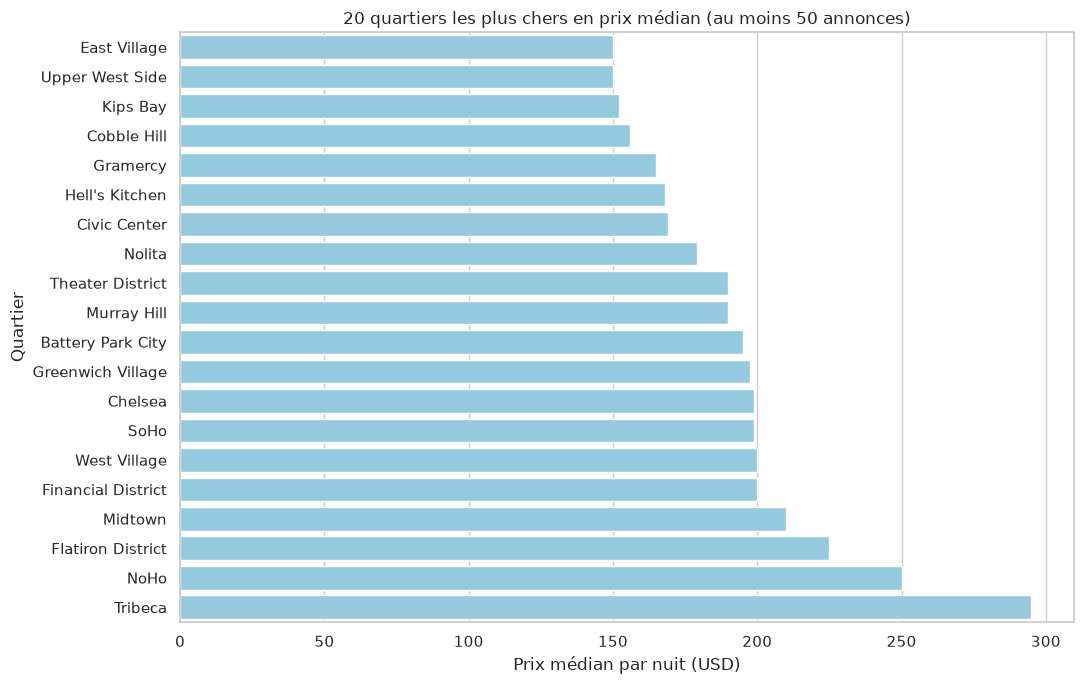

,nombre_annonces,prix_median
neighbourhood,,
Tribeca,177,295.0
NoHo,78,250.0
Flatiron District,80,225.0
Midtown,1545,210.0
Financial District,744,200.0
West Village,768,200.0
SoHo,358,199.0
Chelsea,1113,199.0
Greenwich Village,392,197.5


In [20]:
# Calculer le nombre d'annonces et le prix médian pour chaque quartier.
stats_quartiers = (
    df_clean.groupby("neighbourhood")["price"]
    .agg(nombre_annonces="count", prix_median="median")
)

# On conserve les quartiers avec au moins 50 annonces afin d'éviter de mettre en avant
# un quartier dont la médiane serait calculée sur un effectif très faible.
quartiers_assez_representes = stats_quartiers[stats_quartiers["nombre_annonces"] >= 50]

# Sélectionner les 20 quartiers dont le prix médian est le plus élevé.
# Le dernier tri organise les barres dans un ordre croissant, plus lisible à l'écran.
top_quartiers = (
    quartiers_assez_representes.sort_values("prix_median", ascending=False)
    .head(20).sort_values("prix_median")
)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(
    data=top_quartiers.reset_index(),
    x="prix_median", y="neighbourhood", color="skyblue", ax=ax
)
ax.set_title("20 quartiers les plus chers en prix médian (au moins 50 annonces)")
ax.set_xlabel("Prix médian par nuit (USD)")
ax.set_ylabel("Quartier")
plt.tight_layout()
plt.show()

display(top_quartiers.sort_values("prix_median", ascending=False).round(2))

### Interprétation des quartiers les plus chers

Parmi les quartiers ayant au moins 50 annonces, **Tribeca** présente le prix médian le plus élevé (**295 USD**, pour 177 annonces). Il est suivi de **NoHo (250 USD ; 78 annonces)**, de **Flatiron District (225 USD ; 80 annonces)** et de **Midtown (210 USD ; 1 545 annonces)**. Financial District et West Village affichent chacun une médiane de **200 USD**, avec respectivement 744 et 768 annonces.

Le seuil minimal de 50 annonces réduit le risque de mettre en avant un quartier dont la médiane reposerait sur seulement quelques observations. Il reste néanmoins utile de regarder l'effectif à côté du prix médian : Tribeca a une médiane élevée, mais Midtown repose sur un volume d'annonces beaucoup plus important. Ce classement décrit les quartiers les plus chers parmi ceux suffisamment représentés ; il ne décrit pas tous les quartiers de New York.

### 9.7 Répartition géographique des annonces

Les coordonnées permettent de représenter la localisation des annonces. Pour accélérer l'affichage, un échantillon aléatoire est utilisé si le fichier contient plus de 20 000 lignes. L'échantillonnage concerne uniquement le graphique, pas le CSV final.

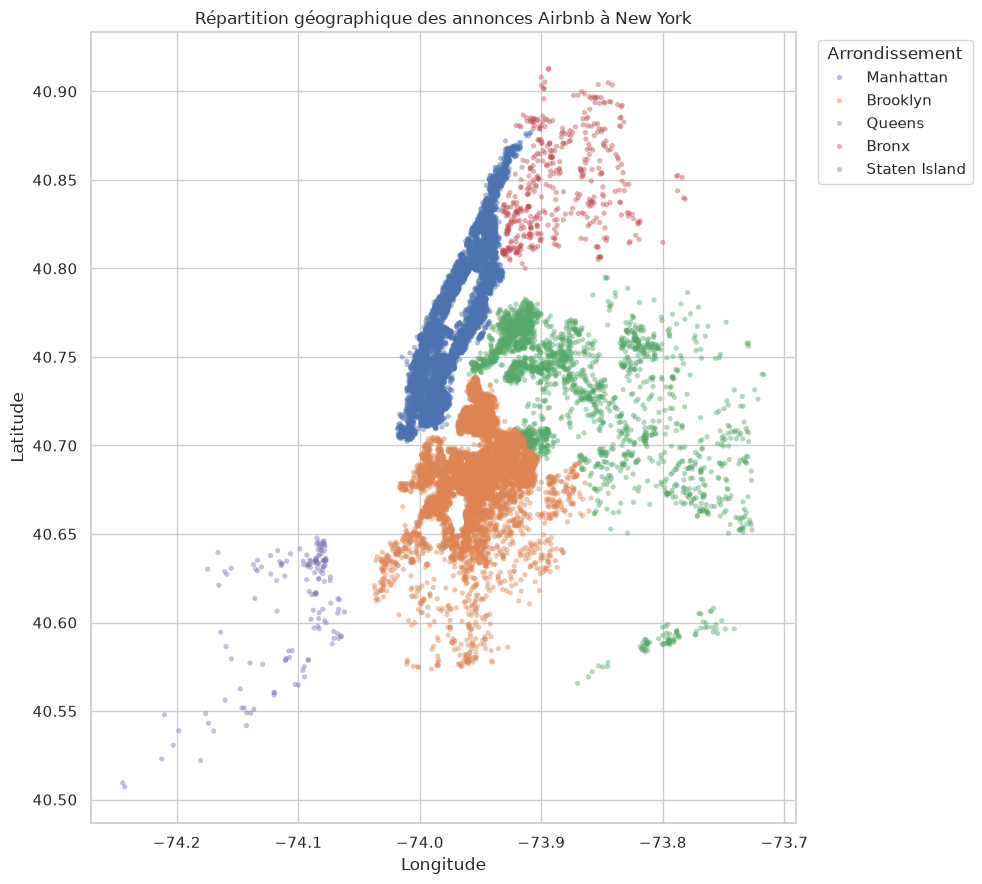

In [21]:
# On écarte uniquement du graphique les annonces sans coordonnées.
# Elles restent dans df_clean et dans le CSV final.
carte = df_clean.dropna(subset=["latitude", "longitude"]).copy()

# Si le nombre de points est très élevé, on prélève un échantillon pour accélérer l'affichage.
# random_state garantit que le même échantillon sera obtenu à chaque exécution.
if len(carte) > 20_000:
    carte = carte.sample(20_000, random_state=42)

# Chaque point représente une annonce ; sa couleur indique l'arrondissement.
fig, ax = plt.subplots(figsize=(10, 9))
sns.scatterplot(
    data=carte, x="longitude", y="latitude", hue="neighbourhood_group",
    alpha=0.45, s=14, linewidth=0, ax=ax
)
ax.set_title("Répartition géographique des annonces Airbnb à New York")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Arrondissement", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interprétation de la carte de répartition géographique

La carte met en évidence une forte concentration de points à Manhattan et à Brooklyn, ce qui rejoint les effectifs observés dans le tableau des arrondissements. Les annonces apparaissent également dans le Queens et le Bronx, mais de manière plus dispersée, tandis que Staten Island présente beaucoup moins de points.

Chaque point représente une annonce et la couleur identifie son arrondissement. Pour accélérer le rendu, la carte utilise un échantillon aléatoire de **20 000 annonces** lorsque le nombre de lignes dépasse ce seuil : la carte est donc une représentation visuelle d'un échantillon, tandis que les statistiques et le CSV reposent sur l'ensemble des **48 884 annonces** nettoyées. La carte montre une distribution spatiale, mais elle ne fournit pas à elle seule une mesure de distance aux attractions ou de fréquentation touristique.

### 9.8 Séjours minimums et valeurs extrêmes

Nous affichons la distribution des séjours minimums en limitant l'axe au 99e percentile pour examiner les valeurs courantes. Les valeurs plus élevées sont comptabilisées à part et restent dans le fichier nettoyé, car un séjour long n'est pas forcément une erreur de saisie.

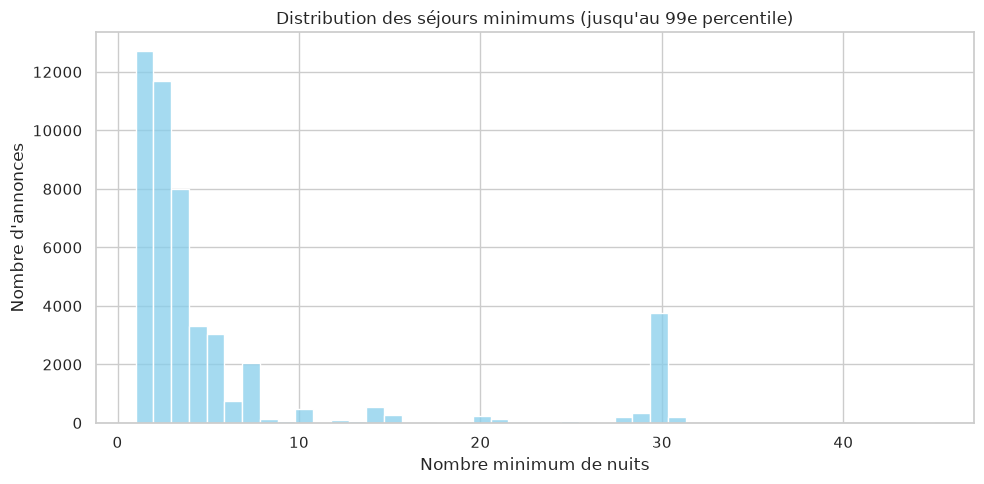

Annonces exigeant plus de 365 nuits minimum : 14
Valeurs extrêmes IQR pour les nuits minimum : 6605


In [22]:
# On convertit les nuits minimums en nombres décimaux pour les graphiques.
nuits = df_clean["minimum_nights"].dropna().astype(float)

# Le 99e percentile limite l'axe du graphique aux valeurs les plus courantes.
# Ce choix d'affichage ne retire aucune observation du DataFrame nettoyé.
seuil_99_nuits = nuits.quantile(0.99) if not nuits.empty else 0

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(nuits[nuits <= seuil_99_nuits], bins=45, color="skyblue", ax=ax)
ax.set_title("Distribution des séjours minimums (jusqu'au 99e percentile)")
ax.set_xlabel("Nombre minimum de nuits")
ax.set_ylabel("Nombre d'annonces")
plt.tight_layout()
plt.show()

# Les indicateurs suivants aident à discuter les séjours très longs et les valeurs atypiques.
print("Annonces exigeant plus de 365 nuits minimum :", int((df_clean["minimum_nights"] > 365).sum()))
print("Valeurs extrêmes IQR pour les nuits minimum :", compter_outliers_iqr(nuits))

### Interprétation des séjours minimums

La distribution est concentrée sur les durées minimales les plus courtes ; dans les statistiques initiales, la médiane est de **3 nuits** et 75 % des observations sont à **5 nuits ou moins**. La règle IQR signale encore **6 605 valeurs atypiques** après nettoyage, et **14 annonces** exigent plus de 365 nuits minimum.

Ces résultats montrent que les conditions de réservation varient fortement selon les annonces. Les valeurs très élevées peuvent correspondre à des règles particulières ou à des annonces destinées à des séjours longs ; elles ne doivent donc pas être supprimées uniquement parce qu'elles dépassent la borne IQR. Si l'objectif métier était strictement l'étude des séjours touristiques de courte durée, une analyse spécifique de ces annonces pourrait être menée séparément.

### 9.9 Corrélations entre variables numériques

La corrélation de Spearman est utilisée pour mesurer des associations monotones et limiter la dépendance aux distributions très asymétriques. Les identifiants ne sont pas inclus, car leurs valeurs numériques n'ont pas de sens analytique direct.

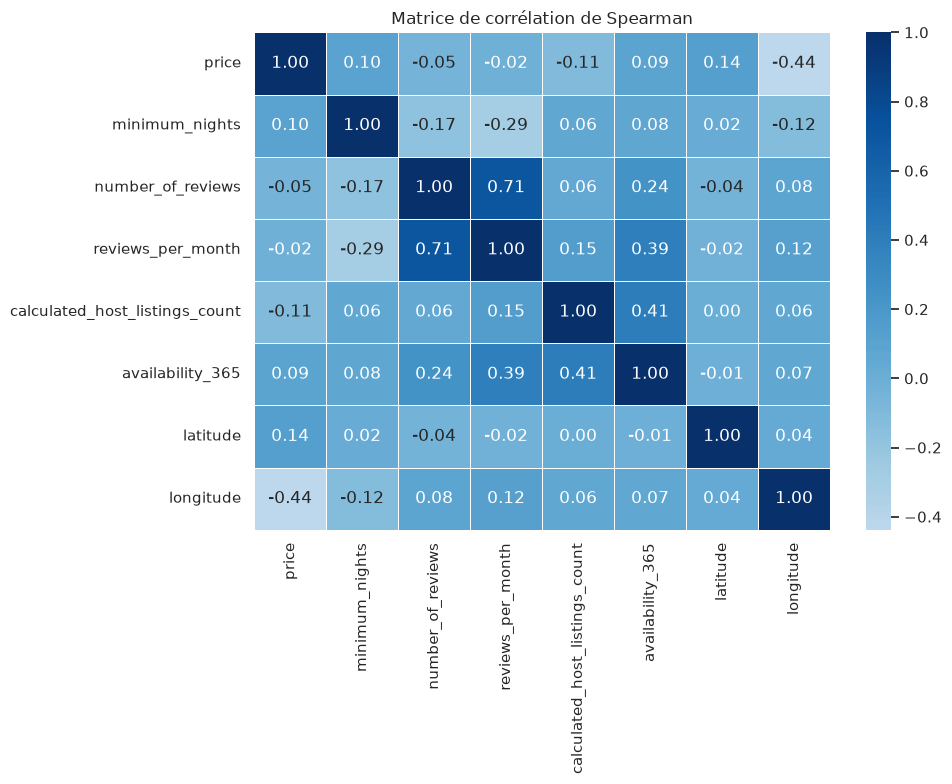

In [23]:
# Liste des variables numériques retenues pour étudier les associations monotones.
# Les identifiants ne sont pas inclus : leur valeur numérique n'a pas de signification analytique.
variables_correlation = [
    "price", "minimum_nights", "number_of_reviews", "reviews_per_month",
    "calculated_host_listings_count", "availability_365", "latitude", "longitude"
]

# Spearman mesure la force et le sens d'une relation monotone ; il est utile avec des
# distributions asymétriques et moins dépendant d'une relation strictement linéaire.
matrice = (
    df_clean[variables_correlation]
    .apply(pd.to_numeric, errors="coerce")
    .corr(method="spearman")
)

# La carte thermique colore les coefficients et affiche leur valeur dans chaque case.
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matrice, annot=True, fmt=".2f", cmap="Blues", center=0, linewidths=0.5, ax=ax)
ax.set_title("Matrice de corrélation de Spearman")
plt.tight_layout()
plt.show()

### Interprétation de la matrice de corrélation de Spearman

La relation la plus marquée avec le prix dans cette matrice est une corrélation négative modérée avec la longitude (**-0,44**). Les liens entre le prix et les autres variables numériques sont plus faibles : latitude (**0,14**), nombre minimal de nuits (**0,10**), disponibilité (**0,09**), nombre d'avis (**-0,05**), avis par mois (**-0,02**) et nombre d'annonces de l'hôte (**-0,11**).

La matrice révèle aussi des associations entre variables explicatives : le nombre d'avis et les avis par mois sont fortement associés (**0,71**), tandis que le nombre d'annonces de l'hôte et la disponibilité présentent une corrélation positive de **0,41**. La durée minimale et les avis par mois affichent une corrélation négative de **-0,29**.

Une corrélation mesure une association, pas une causalité. De plus, la longitude et la latitude servent ici de repères géographiques ; elles peuvent capter des différences de localisation, mais ne disent pas quelle caractéristique précise d'un quartier fait varier le prix.

## 10. Synthèse métier

Les indicateurs suivants résument quelques constats descriptifs calculés à partir des données nettoyées. Ils servent de support à l'interprétation et à la restitution orale.

Il faut rester prudent : les résultats décrivent des associations observées dans des annonces de 2019. Ils ne prouvent pas qu'une caractéristique est la cause d'un prix élevé, et ils ne représentent pas nécessairement le marché actuel.

In [24]:
# Identifier quelques résultats descriptifs à partir du DataFrame nettoyé.
# idxmax() renvoie la catégorie associée à l'effectif ou à la médiane la plus élevée.
arrondissement_plus_annonces = df_clean["neighbourhood_group"].value_counts().idxmax()
arrondissement_prix_median = df_clean.groupby("neighbourhood_group")["price"].median().idxmax()
type_plus_present = df_clean["room_type"].value_counts().idxmax()

print("SYNTHÈSE DESCRIPTIVE")
print("- Arrondissement avec le plus d'annonces :", arrondissement_plus_annonces)
print("- Arrondissement avec le prix médian le plus élevé :", arrondissement_prix_median)
print("- Type de logement le plus représenté :", type_plus_present)
print("- Prix médian global : ${:,.2f}".format(df_clean["price"].median()))
print("- Nombre d'annonces après nettoyage :", f"{len(df_clean):,}".replace(",", " "))

# Ces questions guident l'interprétation, plutôt que de laisser les graphiques sans commentaire.
print("\nÀ discuter dans la restitution :")
print("1. Les écarts de prix entre arrondissements sont-ils importants ?")
print("2. Le type de logement semble-t-il associé au niveau de prix ?")
print("3. Les arrondissements qui concentrent beaucoup d'annonces sont-ils aussi les plus chers ?")
print("4. Quelles limites de qualité ou de représentativité empêchent de généraliser ces observations ?")

SYNTHÈSE DESCRIPTIVE
- Arrondissement avec le plus d'annonces : Manhattan
- Arrondissement avec le prix médian le plus élevé : Manhattan
- Type de logement le plus représenté : Entire home/apt
- Prix médian global : $106.00
- Nombre d'annonces après nettoyage : 48 884

À discuter dans la restitution :
1. Les écarts de prix entre arrondissements sont-ils importants ?
2. Le type de logement semble-t-il associé au niveau de prix ?
3. Les arrondissements qui concentrent beaucoup d'annonces sont-ils aussi les plus chers ?
4. Quelles limites de qualité ou de représentativité empêchent de généraliser ces observations ?


### Interprétation de la synthèse métier

Les indicateurs récapitulent les principaux constats : **Manhattan** concentre le plus grand nombre d'annonces et possède également le prix médian le plus élevé ; le type de logement le plus représenté est le **logement entier** ; le prix médian global est de **106 USD**. L'analyse porte sur **48 884 annonces** après nettoyage.

Ces résultats répondent aux questions métier : l'offre est concentrée à Manhattan et Brooklyn, les tarifs varient selon l'arrondissement et le type d'hébergement, et les prix sont fortement dispersés. Il s'agit d'associations descriptives observées dans les annonces de 2019, et non de preuves de causalité ni d'une description du marché actuel.

## 11. Essai de modélisation — prédiction du prix (régression supervisée)

### 11.1 Définition du problème

Nous allons tester si les caractéristiques d'une annonce peuvent aider à estimer son prix affiché par nuit.

- **Variable cible (`y`) :** `price`, le prix affiché pour une nuit en dollars américains.
- **Type de problème :** régression supervisée, car la cible est une valeur numérique continue.
- **Variables explicatives (`X`) :** localisation, type de logement, coordonnées, durée minimale, informations sur les avis, nombre d'annonces de l'hôte et disponibilité.

Nous n'utiliserons pas `id` et `host_id` comme variables prédictives : ce sont des identifiants, pas des mesures décrivant la valeur du logement. Nous n'utiliserons pas non plus `name` et `host_name`, car ce sont des textes libres difficiles à exploiter proprement dans un premier TP.

### 11.2 Pourquoi comparer plusieurs modèles ?

Nous allons comparer trois approches :

1. **Baseline — médiane :** prédit systématiquement le prix médian observé dans l'échantillon d'entraînement. C'est un point de référence simple ; un modèle de Machine Learning devrait idéalement faire mieux.
2. **Régression Ridge :** modèle linéaire régularisé. Il cherche une relation approximativement linéaire entre les variables préparées et le logarithme du prix.
3. **Random Forest Regressor :** ensemble d'arbres de décision capable de représenter des relations non linéaires et des interactions entre caractéristiques.

### 11.3 Pourquoi transformer le prix avec `log(1 + price)` ?

La distribution des prix est très asymétrique : quelques annonces très chères sont très éloignées de la majorité. Nous entraînons donc les deux modèles sur `log(1 + price)`, ce qui réduit l'influence des grandes valeurs pendant l'apprentissage. Pour l'évaluation, nous reconvertissons les prédictions en dollars afin que les métriques restent faciles à interpréter.

### 11.4 Séparation entraînement / test

Nous réservons 80 % des annonces à l'entraînement et 20 % au test. Le jeu de test reste à l'écart pendant l'apprentissage : il sert uniquement à mesurer la capacité du modèle à prédire des annonces qu'il n'a pas vues.

Les règles de prétraitement (imputation, standardisation et encodage) seront intégrées dans des pipelines scikit-learn. Elles seront donc apprises sur l'échantillon d'entraînement uniquement, ce qui limite le risque de fuite de données (*data leakage*).

### 11.5 Préparation des variables explicatives et séparation des données

Nous créons d'abord une matrice `X` contenant les caractéristiques et une série `y` contenant le prix à prédire.

Nous ajoutons également une variable simple, `has_reviews`, qui indique si l'annonce possède au moins un avis. Cette variable permet de distinguer une annonce sans avis d'une annonce dont le champ `reviews_per_month` est absent.

Enfin, nous séparons `X` et `y` en deux ensembles. Le paramètre `random_state=42` rend la séparation reproductible : à chaque exécution, les mêmes annonces seront normalement affectées aux mêmes ensembles.

In [25]:
# -----------------------------------------------------------------------------
# Définition de la cible et des caractéristiques utilisées pour la régression
# -----------------------------------------------------------------------------

# La cible est le prix affiché par nuit. Le nettoyage a déjà retiré les prix
# manquants, nuls ou négatifs ; nous pouvons donc la convertir en float.
colonne_cible = "price"
y_prix = df_clean[colonne_cible].astype(float)

# Variables catégorielles : elles représentent des catégories, pas des quantités.
colonnes_categorielles_modele = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type"
]

# Variables numériques : elles représentent des mesures ou des compteurs.
colonnes_numeriques_modele = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# On copie seulement les colonnes retenues pour construire la matrice des variables X.
X = df_clean[colonnes_categorielles_modele + colonnes_numeriques_modele].copy()

# Feature Engineering : créer une variable indicatrice qui vaut 1 si l'annonce a
# au moins un avis et 0 si elle n'en a aucun.
# Si le nombre d'avis lui-même est inconnu, on conserve NA au lieu de supposer zéro.
nombre_avis_numerique = pd.to_numeric(X["number_of_reviews"], errors="coerce")
X["has_reviews"] = np.where(
    nombre_avis_numerique.isna(),
    np.nan,
    (nombre_avis_numerique > 0).astype(float)
)

# Ajouter cette nouvelle variable à la liste des colonnes numériques.
colonnes_numeriques_modele = colonnes_numeriques_modele + ["has_reviews"]

# Convertir explicitement les variables numériques en float.
# Cela transforme aussi les valeurs manquantes pandas (pd.NA) en NaN compatibles
# avec les outils de prétraitement de scikit-learn.
for colonne in colonnes_numeriques_modele:
    X[colonne] = pd.to_numeric(X[colonne], errors="coerce").astype(float)

# Convertir les catégories en chaînes de caractères ; les valeurs manquantes éventuelles
# seront gérées ensuite par SimpleImputer dans le pipeline.
for colonne in colonnes_categorielles_modele:
    X[colonne] = X[colonne].astype("object")

# Vérifier les dimensions et la liste des variables avant l'entraînement.
print("Nombre d'annonces utilisables :", len(X))
print("Nombre de variables explicatives :", X.shape[1])
print("Variables catégorielles :", colonnes_categorielles_modele)
print("Variables numériques :", colonnes_numeriques_modele)
print("\nAperçu des variables explicatives :")
display(X.head())

# Séparer les observations en apprentissage (80 %) et test (20 %).
# Le même état aléatoire permet de reproduire exactement cette séparation.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_prix,
    test_size=0.20,
    random_state=42
)

# La transformation logarithmique est appliquée après la séparation.
# Les modèles apprennent ainsi à prédire le logarithme du prix, et non le prix brut.
y_train_log = np.log1p(y_train)

print("\nTaille de l'échantillon d'entraînement :", X_train.shape[0])
print("Taille de l'échantillon de test :", X_test.shape[0])
print("Part réservée au test : 20 %")

Nombre d'annonces utilisables : 48884
Nombre de variables explicatives : 11
Variables catégorielles : ['neighbourhood_group', 'neighbourhood', 'room_type']
Variables numériques : ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'has_reviews']

Aperçu des variables explicatives :


,neighbourhood_group,neighbourhood,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews
0,Brooklyn,Kensington,Private room,40.64749,-73.97237,1.0,9.0,0.21,6.0,365.0,1.0
1,Manhattan,Midtown,Entire home/apt,40.75362,-73.98377,1.0,45.0,0.38,2.0,355.0,1.0
2,Manhattan,Harlem,Private room,40.80902,-73.94190,3.0,0.0,NaN,1.0,365.0,0.0
3,Brooklyn,Clinton Hill,Entire home/apt,40.68514,-73.95976,1.0,270.0,4.64,1.0,194.0,1.0
4,Manhattan,East Harlem,Entire home/apt,40.79851,-73.94399,10.0,9.0,0.10,1.0,0.0,1.0



Taille de l'échantillon d'entraînement : 39107
Taille de l'échantillon de test : 9777
Part réservée au test : 20 %


### Interprétation de la préparation des variables et de la séparation

La matrice explicative comprend **11 variables** : 3 variables catégorielles (`neighbourhood_group`, `neighbourhood`, `room_type`) et 8 variables numériques, dont `has_reviews`, créée par *feature engineering* pour distinguer les annonces ayant au moins un avis de celles qui n'en ont aucun.

Les **48 884 annonces** sont réparties en **39 107 observations d'entraînement** et **9 777 observations de test**. Le modèle apprend sur l'ensemble d'entraînement ; le test reste réservé à l'évaluation finale. Cette séparation limite le risque de mesurer les performances sur des annonces déjà vues. Les identifiants et les textes libres ne sont pas utilisés comme prédicteurs, car ils n'apportent pas ici de mesure directement interprétable et exploitable.

### 11.6 Prétraitement des variables et entraînement des modèles

Les algorithmes de régression ne peuvent pas exploiter directement les catégories textuelles comme `Manhattan` ou `Private room`. Nous préparons donc les données de cette manière :

- **Variables numériques :** les valeurs manquantes éventuelles sont remplacées par la médiane de la colonne ; une standardisation est ensuite appliquée pour le modèle Ridge.
- **Variables catégorielles :** les valeurs manquantes éventuelles sont remplacées par la modalité la plus fréquente, puis `OneHotEncoder` transforme les catégories en colonnes numériques.

`ColumnTransformer` applique le bon traitement aux bonnes colonnes. `Pipeline` enchaîne le prétraitement et le modèle. Comme ces opérations sont entraînées à l'intérieur du pipeline, elles apprennent leurs paramètres uniquement avec `X_train`.

Nous entraînons ensuite les deux modèles de Machine Learning sur `y_train_log`. Le modèle de référence, lui, prédit simplement la médiane des prix de l'échantillon d'entraînement.

In [26]:
# -----------------------------------------------------------------------------
# Fonction qui construit un préprocesseur indépendant pour chaque modèle
# -----------------------------------------------------------------------------
def creer_preprocesseur(standardiser_numerique=True):
    """Prépare les colonnes numériques et catégorielles avant la régression.

    Créer un préprocesseur à chaque appel évite de partager le même objet
    entre plusieurs pipelines, chaque modèle devant apprendre ses propres
    paramètres de prétraitement à partir de l'échantillon d'entraînement.
    """

    # Pour les variables numériques :
    # 1) SimpleImputer remplace les valeurs manquantes par la médiane de la colonne ;
    # 2) StandardScaler centre et réduit les variables, ce qui aide le modèle Ridge.
    etapes_numeriques = [("imputation", SimpleImputer(strategy="median"))]

    # La standardisation est utile pour Ridge. Elle n'est pas nécessaire pour
    # une forêt aléatoire, qui prend ses décisions par seuils sur les variables.
    if standardiser_numerique:
        etapes_numeriques.append(("standardisation", StandardScaler()))

    preparation_numerique = Pipeline(steps=etapes_numeriques)

    # Pour les variables catégorielles :
    # 1) SimpleImputer remplace une catégorie manquante par la catégorie la plus fréquente ;
    # 2) OneHotEncoder crée une colonne indicatrice pour chaque modalité rencontrée.
    # handle_unknown="ignore" évite une erreur si une catégorie du jeu de test n'a pas
    # été rencontrée pendant l'entraînement.
    preparation_categorielle = Pipeline(steps=[
        ("imputation", SimpleImputer(strategy="most_frequent")),
        ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
    ])

    # ColumnTransformer choisit le pipeline à appliquer selon le nom des colonnes.
    return ColumnTransformer(
        transformers=[
            ("numerique", preparation_numerique, colonnes_numeriques_modele),
            ("categorielle", preparation_categorielle, colonnes_categorielles_modele)
        ]
    )

# -----------------------------------------------------------------------------
# Modèle 1 : régression Ridge
# -----------------------------------------------------------------------------
# Ridge est une régression linéaire avec régularisation L2. Le paramètre alpha
# contrôle l'intensité de la régularisation ; il limite les coefficients trop élevés.
modele_ridge = Pipeline(steps=[
    ("preparation", creer_preprocesseur(standardiser_numerique=True)),
    ("modele", Ridge(alpha=10.0))
])

# -----------------------------------------------------------------------------
# Modèle 2 : forêt aléatoire de régression
# -----------------------------------------------------------------------------
# Une forêt aléatoire entraîne plusieurs arbres de décision et combine leurs résultats.
# Les paramètres choisis limitent quelque peu la complexité pour un TP sur ordinateur.
modele_foret = Pipeline(steps=[
    ("preparation", creer_preprocesseur(standardiser_numerique=False)),
    ("modele", RandomForestRegressor(
        n_estimators=60,       # Nombre d'arbres dans la forêt.
        max_depth=18,          # Profondeur maximale de chaque arbre.
        min_samples_leaf=3,    # Au moins trois observations par feuille.
        max_features=0.8,      # Part des variables examinées à chaque séparation.
        random_state=42,       # Résultats reproductibles.
        n_jobs=-1              # Utiliser les cœurs disponibles du processeur.
    ))
])

# Entraîner les modèles : fit() apprend les paramètres de préparation et le modèle.
print("Entraînement de la régression Ridge...")
modele_ridge.fit(X_train, y_train_log)

print("Entraînement de la forêt aléatoire...")
modele_foret.fit(X_train, y_train_log)

print("\nLes deux modèles ont terminé leur entraînement.")

Entraînement de la régression Ridge...
Entraînement de la forêt aléatoire...

Les deux modèles ont terminé leur entraînement.


### Interprétation de l'entraînement des modèles

Deux modèles apprennent à partir des mêmes variables préparées : Ridge, qui représente une relation linéaire régularisée, et la forêt aléatoire, qui combine plusieurs arbres et peut apprendre des relations non linéaires. La baseline ne cherche pas de relation : elle prédit simplement la médiane des prix de l'échantillon d'entraînement.

Le prétraitement est inclus dans les pipelines. Les médianes d'imputation, les paramètres de standardisation et les catégories de l'encodage sont donc appris sur l'entraînement, puis appliqués au test. Cette organisation réduit le risque de fuite de données. La comparaison des métriques dans la cellule suivante permettra de vérifier si les modèles apportent un gain par rapport à la baseline.

### 11.7 Évaluation et comparaison des performances

Nous évaluons les modèles sur les annonces du jeu de test.

Les prédictions produites par les modèles sont d'abord exprimées sur l'échelle logarithmique. Nous appliquons `expm1` pour revenir à des montants en dollars. Une prédiction négative n'ayant pas de sens pour un prix, nous la ramenons à zéro avant le calcul des métriques.

Les métriques affichées sont :

- **MAE (Mean Absolute Error) :** erreur absolue moyenne, en dollars. Plus elle est faible, mieux c'est.
- **RMSE (Root Mean Squared Error) :** racine de l'erreur quadratique moyenne, également en dollars. Elle pénalise davantage les grandes erreurs.
- **MedAE (Median Absolute Error) :** médiane des erreurs absolues. Elle est moins sensible à quelques erreurs extrêmes.
- **R² :** part de la variabilité de la cible expliquée par le modèle selon le calcul du coefficient de détermination. Une valeur proche de 1 est généralement meilleure ; une valeur négative indique que le modèle fait moins bien qu'une prédiction constante égale à la moyenne du jeu de test.

La comparaison avec la baseline est importante : un modèle plus complexe n'est utile que s'il apporte un gain par rapport à une règle très simple.

In [27]:
# -----------------------------------------------------------------------------
# Prédictions sur le jeu de test et conversion en dollars
# -----------------------------------------------------------------------------

# Baseline : toujours prédire la médiane du prix dans l'échantillon d'entraînement.
# Elle ne réalise aucun apprentissage complexe et sert de point de comparaison.
predictions_prix = {
    "Baseline — médiane": np.full(len(y_test), y_train.median(), dtype=float)
}

# Les modèles entraînés prédisent log(1 + prix). On applique expm1 pour revenir en USD.
# np.maximum(..., 0) empêche d'obtenir un tarif négatif après reconversion.
pred_ridge_log = modele_ridge.predict(X_test)
predictions_prix["Régression Ridge"] = np.expm1(np.maximum(pred_ridge_log, 0))

pred_foret_log = modele_foret.predict(X_test)
predictions_prix["Forêt aléatoire"] = np.expm1(np.maximum(pred_foret_log, 0))

# -----------------------------------------------------------------------------
# Calcul des métriques de régression
# -----------------------------------------------------------------------------
resultats_modeles = []

for nom_modele, prix_predits in predictions_prix.items():
    # MAE : moyenne des écarts absolus entre les prix réels et prédits.
    mae = mean_absolute_error(y_test, prix_predits)

    # RMSE : racine de la moyenne des carrés des erreurs.
    rmse = np.sqrt(mean_squared_error(y_test, prix_predits))

    # MedAE : médiane des erreurs absolues, moins influencée par les grandes erreurs.
    medae = median_absolute_error(y_test, prix_predits)

    # R² : mesure la performance par rapport à une prédiction constante égale à la moyenne.
    r2 = r2_score(y_test, prix_predits)

    resultats_modeles.append({
        "Modèle": nom_modele,
        "MAE (USD)": mae,
        "RMSE (USD)": rmse,
        "MedAE (USD)": medae,
        "R²": r2
    })

# Le tableau est trié selon la MAE : le modèle avec l'erreur absolue moyenne
# la plus faible apparaît en premier. Les résultats sont propres à ce jeu de test.
comparaison_modeles = (
    pd.DataFrame(resultats_modeles)
    .sort_values("MAE (USD)")
    .reset_index(drop=True)
)

display(comparaison_modeles.round(3))

# Afficher le nom du modèle qui possède la MAE la plus faible sur notre échantillon de test.
meilleur_modele_mae = comparaison_modeles.iloc[0]["Modèle"]
print("Modèle avec la MAE la plus faible sur le jeu de test :", meilleur_modele_mae)
print("Attention : ce résultat ne garantit pas que ce modèle sera meilleur sur d'autres données.")

,Modèle,MAE (USD),RMSE (USD),MedAE (USD),R²
0,Forêt aléatoire,55.494,178.665,23.501,0.203
1,Régression Ridge,59.720,186.575,26.585,0.131
2,Baseline — médiane,82.731,205.101,46.000,-0.051


Modèle avec la MAE la plus faible sur le jeu de test : Forêt aléatoire
Attention : ce résultat ne garantit pas que ce modèle sera meilleur sur d'autres données.


### Interprétation du tableau de comparaison des modèles

Sur les **9 777 annonces du jeu de test**, la **forêt aléatoire** obtient les meilleurs résultats parmi les trois approches : MAE de **55,49 USD**, RMSE de **178,67 USD**, MedAE de **23,50 USD** et R² de **0,203**. Ridge arrive ensuite avec une MAE de **59,72 USD** et un R² de **0,131**. La baseline fondée sur la médiane est moins performante, avec une MAE de **82,73 USD** et un R² de **-0,051**.

La MAE de la forêt aléatoire est inférieure d'environ **32,9 %** à celle de la baseline : le modèle apporte donc un gain sur ce jeu de test. Toutefois, son R² de **0,203** indique qu'il n'explique qu'une part limitée de la variabilité des prix selon cette mesure. Le RMSE, nettement supérieur à la MAE, signale que certaines erreurs importantes pèsent fortement sur le résultat, ce qui est cohérent avec la présence de prix très élevés.

La forêt aléatoire est donc le meilleur modèle **parmi ceux testés et sur ce jeu de test** ; cela ne signifie pas que sa précision est suffisante pour fixer automatiquement des tarifs ni qu'elle sera supérieure sur de nouvelles données.

### 11.8 Visualisation des prédictions et des erreurs

Les graphiques permettent de compléter les métriques numériques.

- Le graphique **prix réel / prix prédit** permet de voir si les prédictions suivent globalement les valeurs observées. Les deux axes utilisent `log(1 + prix)` afin de rendre visibles les petits et les grands tarifs sur le même graphique.
- Le graphique des **erreurs de prédiction** montre comment se répartissent les écarts en dollars. Une erreur positive signifie que le prix réel est supérieur au prix prédit ; une erreur négative signifie que le modèle a surestimé le prix.

Pour ne pas surcharger le graphique, nous utilisons au maximum 5 000 annonces du jeu de test. Cet échantillonnage ne modifie pas l'évaluation calculée avec l'ensemble du jeu de test.

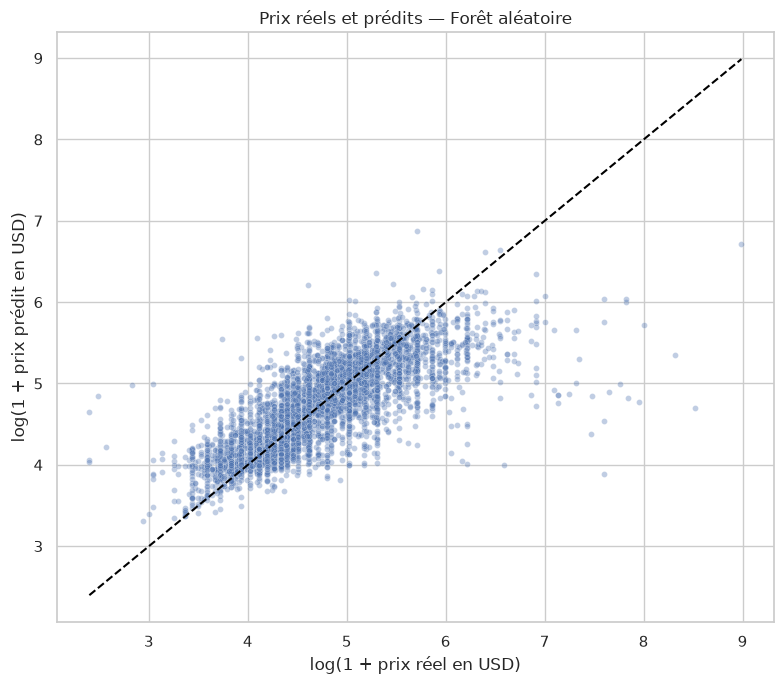

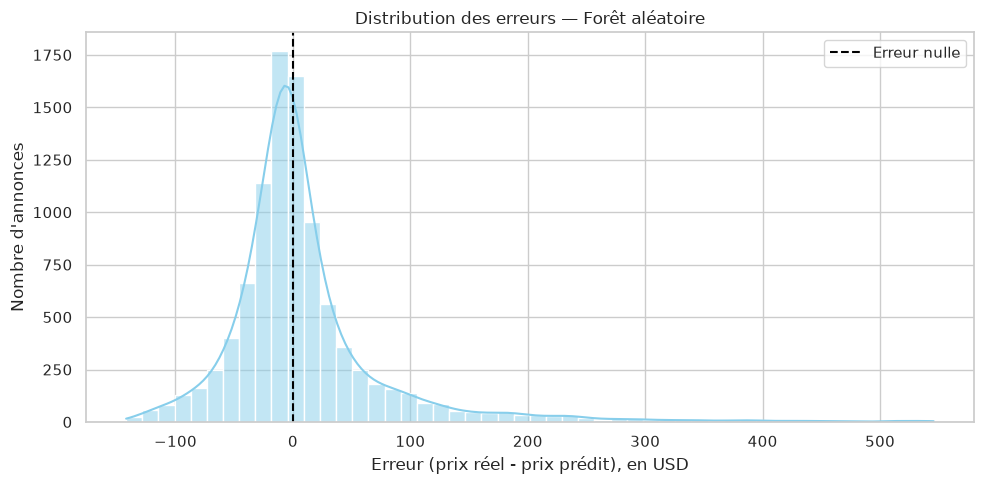

Erreur médiane signée (USD) : -3.69
Erreur absolue médiane (USD) : 23.5


In [28]:
# Choisir le modèle qui obtient la MAE la plus faible pour illustrer ses prédictions.
# Le tableau de métriques reste la référence pour comparer tous les modèles.
meilleurs_prix_predits = predictions_prix[meilleur_modele_mae]

# Constituer un tableau qui associe chaque prix réel à sa prédiction.
df_predictions = pd.DataFrame({
    "Prix réel (USD)": y_test.to_numpy(),
    "Prix prédit (USD)": meilleurs_prix_predits
})

# Échantillonner uniquement pour l'affichage si le jeu de test contient plus de 5 000 lignes.
if len(df_predictions) > 5_000:
    df_predictions_graph = df_predictions.sample(5_000, random_state=42)
else:
    df_predictions_graph = df_predictions.copy()

# Graphique 1 : comparaison des prix en échelle log(1 + prix).
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=df_predictions_graph,
    x=np.log1p(df_predictions_graph["Prix réel (USD)"]),
    y=np.log1p(df_predictions_graph["Prix prédit (USD)"]),
    alpha=0.35,
    s=18,
    ax=ax
)

# La diagonale représente une prédiction parfaite : prix prédit = prix réel.
limite_min = min(
    np.log1p(df_predictions_graph["Prix réel (USD)"]).min(),
    np.log1p(df_predictions_graph["Prix prédit (USD)"]).min()
)
limite_max = max(
    np.log1p(df_predictions_graph["Prix réel (USD)"]).max(),
    np.log1p(df_predictions_graph["Prix prédit (USD)"]).max()
)
ax.plot([limite_min, limite_max], [limite_min, limite_max], linestyle="--", color="black")
ax.set_title(f"Prix réels et prédits — {meilleur_modele_mae}")
ax.set_xlabel("log(1 + prix réel en USD)")
ax.set_ylabel("log(1 + prix prédit en USD)")
plt.tight_layout()
plt.show()

# Graphique 2 : erreur = prix réel - prix prédit.
# Une erreur proche de zéro signifie que la prédiction est proche de la valeur réelle.
df_predictions["Erreur (USD)"] = (
    df_predictions["Prix réel (USD)"] - df_predictions["Prix prédit (USD)"]
)

# Pour rendre l'histogramme lisible, on limite l'affichage des erreurs au 1er-99e percentile.
# Les métriques calculées plus haut utilisent toutefois toutes les observations du jeu de test.
borne_erreur_basse, borne_erreur_haute = df_predictions["Erreur (USD)"].quantile([0.01, 0.99])
erreurs_affichees = df_predictions.loc[
    df_predictions["Erreur (USD)"].between(borne_erreur_basse, borne_erreur_haute),
    "Erreur (USD)"
]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(erreurs_affichees, bins=50, kde=True, color="skyblue", ax=ax)
ax.axvline(0, color="black", linestyle="--", label="Erreur nulle")
ax.set_title(f"Distribution des erreurs — {meilleur_modele_mae}")
ax.set_xlabel("Erreur (prix réel - prix prédit), en USD")
ax.set_ylabel("Nombre d'annonces")
ax.legend()
plt.tight_layout()
plt.show()

print("Erreur médiane signée (USD) :", round(df_predictions["Erreur (USD)"].median(), 2))
print("Erreur absolue médiane (USD) :", round(median_absolute_error(y_test, meilleurs_prix_predits), 2))

### Interprétation des prédictions et de la distribution des erreurs

Sur le nuage de points, une prédiction parfaite se situerait sur la diagonale. Les points suivent globalement une tendance croissante, mais ils restent dispersés autour de cette ligne. Les prédictions sont davantage regroupées vers la zone centrale : les tarifs les plus élevés sont souvent sous-estimés, tandis que certains tarifs plus faibles peuvent être surestimés. Le modèle a donc tendance à lisser les extrêmes et à revenir vers des valeurs plus centrales.

L'histogramme des erreurs est concentré autour de zéro, mais il présente une longue queue du côté positif. Comme l'erreur est calculée par **prix réel moins prix prédit**, une erreur positive signifie que le modèle a sous-estimé le prix réel ; une erreur négative signifie qu'il l'a surestimé. La médiane signée est de **-3,69 USD**, ce qui indique une légère surestimation au niveau de l'erreur médiane, tandis que la médiane des erreurs absolues est de **23,50 USD**.

Attention : l'histogramme masque les 1 % d'erreurs les plus faibles et les 1 % les plus élevées uniquement pour améliorer la lisibilité. Les métriques présentées précédemment, elles, sont calculées sur les **9 777 observations** du jeu de test.

### 11.9 Importance des variables et interprétation

La forêt aléatoire calcule une importance par variable à partir de la contribution des caractéristiques aux séparations des arbres. Nous affichons les 15 caractéristiques les plus importantes.

**Précaution :** l'importance affichée par une forêt aléatoire ne démontre pas une relation de cause à effet. Elle indique seulement que le modèle s'est appuyé sur ces caractéristiques pour effectuer ses prédictions. Les variables catégorielles avec beaucoup de modalités peuvent aussi être favorisées par cette mesure d'importance.

À la fin de cette section, discutez les questions suivantes avec votre binôme :

1. Lequel des modèles fait mieux que la baseline selon la MAE ?
2. L'écart entre la MAE et la RMSE indique-t-il la présence de quelques erreurs importantes ?
3. Les variables importantes ont-elles du sens du point de vue touristique ?
4. Quelles informations absentes du dataset pourraient améliorer la prédiction (surface, nombre de chambres, équipements, capacité d'accueil, etc.) ?
5. Pourquoi ne peut-on pas conclure qu'une variable importante est la cause d'un prix plus élevé ?

,Variable transformée,Importance
231,categorielle__room_type_Entire home/apt,0.4027
1,numerique__longitude,0.1393
0,numerique__latitude,0.1064
6,numerique__availability_365,0.0669
232,categorielle__room_type_Private room,0.0559
2,numerique__minimum_nights,0.0430
10,categorielle__neighbourhood_group_Manhattan,0.0387
4,numerique__reviews_per_month,0.0364
3,numerique__number_of_reviews,0.0338
5,numerique__calculated_host_listings_count,0.0267


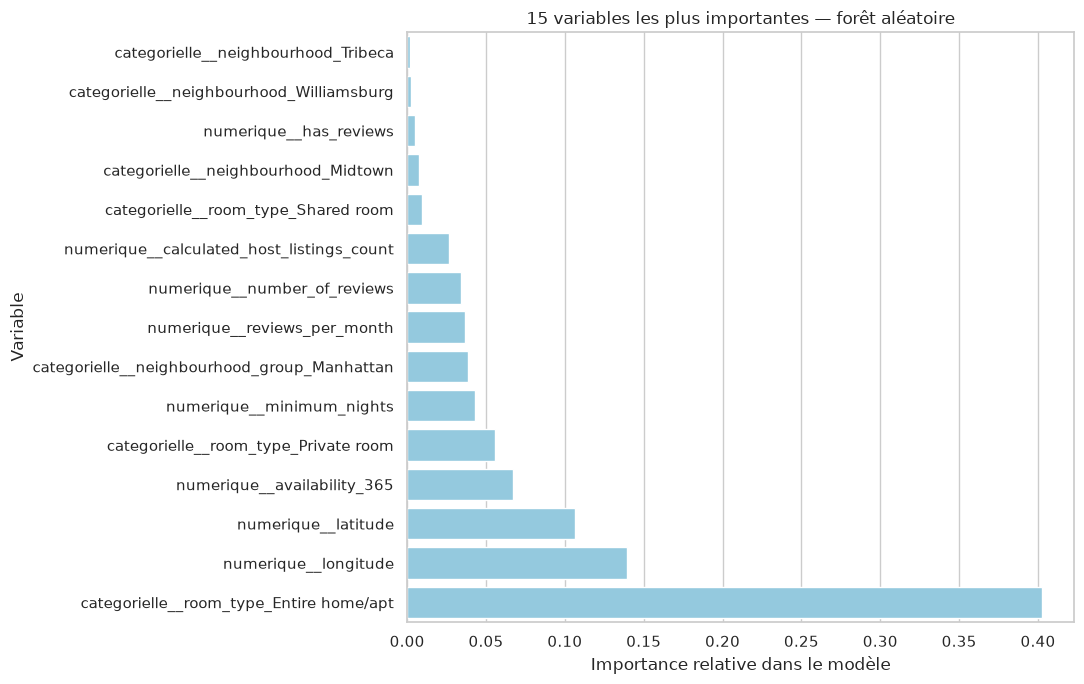

In [29]:
# Extraire le pipeline de la forêt aléatoire déjà entraînée.
# Le préprocesseur connaît les noms des colonnes créées par le OneHotEncoder.
preparation_foret = modele_foret.named_steps["preparation"]
noms_variables_transformees = preparation_foret.get_feature_names_out()

# Récupérer les importances calculées par les arbres de la forêt.
importances = modele_foret.named_steps["modele"].feature_importances_

# Associer chaque importance au nom de la variable correspondante.
importance_variables = (
    pd.DataFrame({
        "Variable transformée": noms_variables_transformees,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .head(15)
    .sort_values("Importance")
)

display(importance_variables.sort_values("Importance", ascending=False).round(4))

# Barplot horizontal : les variables les plus importantes apparaissent en haut.
fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(
    data=importance_variables,
    x="Importance",
    y="Variable transformée",
    color="skyblue",
    ax=ax
)
ax.set_title("15 variables les plus importantes — forêt aléatoire")
ax.set_xlabel("Importance relative dans le modèle")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.show()

### Interprétation de l'importance des variables

La variable transformée la plus importante est la modalité **`room_type_Entire home/apt` (0,4027)**, soit environ 40,27 % de l'importance totale affichée. Viennent ensuite la longitude (**0,1393**), la latitude (**0,1064**), la disponibilité sur 365 jours (**0,0669**) et la modalité `room_type_Private room` (**0,0559**). Le type de logement et la localisation occupent donc une place importante dans les décisions de la forêt aléatoire.

Ces importances indiquent quelles variables ont le plus contribué aux séparations effectuées par les arbres du modèle. Elles ne mesurent pas un effet causal et ne disent pas qu'une caractéristique fait augmenter ou diminuer le prix. Les variables catégorielles ont été transformées en indicateurs binaires par OneHotEncoder : les lignes affichées correspondent donc à des modalités précises, et non toujours à une variable d'origine entière.

## 12. Vérifications finales et export du CSV nettoyé

Avant l'export, nous vérifions les règles essentielles du fichier final : unicité de l'identifiant, prix strictement positif, séjours minimums valides lorsqu'ils sont renseignés et disponibilité comprise entre 0 et 365 jours lorsqu'elle est renseignée.

Le fichier source n'est jamais écrasé. Le CSV nettoyé sera enregistré dans `outputs/AB_NYC_2019_cleaned.csv`.

Après l'exécution de la section de modélisation, cette cellule permet donc de produire le deuxième livrable demandé : le fichier CSV prêt à être exploité.

In [30]:
# -----------------------------------------------------------------------------
# Vérifications finales avant l'export du CSV nettoyé
# -----------------------------------------------------------------------------
# Ces assertions vérifient les règles essentielles décidées pendant le nettoyage.
# Si une condition n'est pas respectée, le notebook s'arrête avec un message explicite.
assert df_clean["id"].notna().all(), "Des identifiants manquants subsistent."
assert df_clean["id"].is_unique, "Des identifiants d'annonce sont encore dupliqués."
assert (
    df_clean["price"].notna().all() and (df_clean["price"] > 0).all()
), "Prix manquants ou non positifs détectés."
assert not (df_clean["minimum_nights"].dropna() <= 0).any(), "Séjour minimum nul ou négatif détecté."
assert df_clean["availability_365"].dropna().between(0, 365).all(), "Disponibilité hors de [0, 365]."
assert pd.api.types.is_datetime64_any_dtype(df_clean["last_review"]), "last_review n'est pas au format date."

# -----------------------------------------------------------------------------
# Export du CSV nettoyé
# -----------------------------------------------------------------------------
# index=False évite d'ajouter une colonne artificielle contenant l'index pandas.
# utf-8-sig améliore la compatibilité des caractères accentués avec certains tableurs.
# date_format impose un format de date lisible et homogène dans le fichier exporté.
# na_rep="" conserve les valeurs manquantes sous forme de cellules vides.
df_clean.to_csv(
    CLEAN_FILE,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
    na_rep=""
)

print("Export terminé :", CLEAN_FILE.resolve())
print("Taille du fichier :", round(CLEAN_FILE.stat().st_size / (1024**2), 2), "Mo")
print("Dimensions du CSV nettoyé :", df_clean.shape)

Export terminé : /home/juste-agbo/Documents/Formations_online/Special_Machine_Learning_PIIA_2/Introduction_machine_learning/TP_Nettoyage_de_donnees/airbnb_nyc_project/airbnb_nyc_tourism_analysis/notebooks/outputs/AB_NYC_2019_cleaned.csv
Taille du fichier : 6.84 Mo
Dimensions du CSV nettoyé : (48884, 16)


### Interprétation des vérifications finales et de l'export

Si les assertions s'exécutent sans erreur, cela confirme que le fichier final respecte les règles essentielles définies dans ce TP : identifiants présents et uniques, prix strictement positifs, durées minimales positives lorsqu'elles sont renseignées, disponibilités comprises entre 0 et 365 jours et date du dernier avis stockée au bon format.

L'export produit un fichier CSV de **48 884 lignes et 16 colonnes**, nommé `AB_NYC_2019_cleaned.csv`. Le fichier brut est conservé séparément ; le CSV nettoyé constitue le livrable de données à remettre avec le notebook.

## 13. Conclusion et limites

### Bilan du nettoyage des données

Le fichier initial contenait **48 895 annonces et 16 variables**. Le diagnostic a mis en évidence 20 141 cellules manquantes, principalement dans les champs liés aux avis, ainsi que 11 prix nuls ou négatifs. Aucun doublon exact ni identifiant d'annonce dupliqué n'a été détecté.

Le nettoyage a consisté à harmoniser les textes, convertir les variables vers des types adaptés, traiter les absences des noms par des libellés explicites et écarter les 11 annonces dont le prix n'était pas strictement positif. Les valeurs extrêmes de prix et de séjours minimums ont été conservées lorsqu'elles n'étaient pas manifestement impossibles. Le fichier final comprend **48 884 annonces**, soit **99,98 %** du volume initial.

Les 10 051 valeurs manquantes restantes dans `last_review` et `reviews_per_month` correspondent à des annonces sans avis. Elles ont été conservées, car elles décrivent une absence structurelle d'avis et non une information manquante pour une annonce qui aurait déjà reçu des avis.

### Principaux enseignements de l'analyse exploratoire

L'offre est fortement concentrée à **Manhattan (44,31 %)** et **Brooklyn (41,11 %)**, qui regroupent ensemble environ **85,42 %** des annonces. Les logements entiers représentent **51,97 %** de l'offre, les chambres privées **45,66 %** et les chambres partagées **2,37 %**.

Le prix médian d'une nuit est de **106 USD**, inférieur au prix moyen de **152,76 USD** : cet écart traduit une distribution asymétrique vers les tarifs élevés. Manhattan présente le prix médian le plus élevé (**150 USD**), devant Brooklyn (**90 USD**). Selon le type de logement, la médiane atteint **160 USD** pour un logement entier, **70 USD** pour une chambre privée et **45 USD** pour une chambre partagée. Ces résultats décrivent des différences observées dans les annonces de 2019 ; ils ne démontrent pas de relations causales.

La carte confirme la concentration spatiale des annonces à Manhattan et Brooklyn. La matrice de Spearman montre notamment une association négative modérée entre le prix et la longitude (**-0,44**), tandis que plusieurs autres associations avec le prix sont faibles. Les avis mensuels et le nombre total d'avis sont, eux, fortement associés (**0,71**).

### Bilan de l'essai de modélisation

Une régression supervisée a été testée pour estimer le prix affiché par nuit à partir de 11 variables explicatives. Les 48 884 annonces ont été réparties en 39 107 observations d'entraînement et 9 777 observations de test. Trois approches ont été comparées : une baseline fondée sur la médiane, une régression Ridge et une forêt aléatoire.

La forêt aléatoire obtient la meilleure MAE sur le jeu de test (**55,49 USD**), devant Ridge (**59,72 USD**) et la baseline (**82,73 USD**). Sa MAE est environ 32,9 % plus faible que celle de la baseline. Cependant, son **R² de 0,203** reste modeste et son **RMSE de 178,67 USD** révèle la présence de certaines erreurs importantes, probablement accentuées par les annonces aux tarifs extrêmes. La forêt aléatoire est donc la meilleure des approches testées dans cette expérience, mais le modèle reste perfectible et ne doit pas être considéré comme un outil de tarification prêt à l'emploi.

L'importance des variables place en tête le type de logement (`Entire home/apt`), puis la longitude et la latitude. Cette importance décrit la manière dont le modèle utilise les variables ; elle ne démontre pas qu'elles causent les variations de prix.

### Limites de l'étude

1. Les données décrivent les annonces de **2019** et ne représentent pas nécessairement le marché actuel.
2. Le prix affiché ne renseigne pas à lui seul sur le prix final payé, les frais ou les taxes.
3. La disponibilité ne correspond pas à l'occupation réelle du logement.
4. Les avis ne couvrent pas toutes les réservations et ne constituent pas une mesure parfaite de la demande touristique.
5. Certaines caractéristiques importantes pour la tarification (surface, capacité d'accueil, équipements, état du logement, qualité des photos ou distance aux attractions) ne figurent pas dans le fichier.
6. Les valeurs extrêmes conservées mériteraient une analyse spécifique selon l'objectif métier.
7. L'essai de modélisation est une expérimentation pédagogique réalisée sur un seul jeu de test ; une validation plus poussée et des données plus récentes seraient nécessaires avant tout usage opérationnel.

### Conclusion générale

Ce TP nous a permis de parcourir une démarche complète de Data Science : comprendre le contexte touristique, diagnostiquer la qualité des données, justifier les corrections, explorer les annonces à l'aide de tableaux et de visualisations, puis effectuer un premier essai de régression. Le travail montre qu'un nettoyage pertinent ne consiste pas à supprimer toutes les valeurs atypiques ou toutes les cases vides, mais à prendre des décisions cohérentes avec le sens métier des variables.

### Sources

- Kaggle : [New York City Airbnb Open Data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data)
- KaggleHub : [documentation du téléchargement des jeux de données](https://github.com/Kaggle/kagglehub)
- scikit-learn : [documentation officielle](https://scikit-learn.org/stable/)
